## Proyecto de Localización y Clasificación de Vehículos

**Integrantes:**
- Hector Betancourt Lopez
- Valentina Giraldo Gaviria

#### Objetivo del proyecto

En este trabajo se construye un modelo de visión por computadora capaz de resolver simultáneamente dos tareas:

1. **Clasificación** de la clase del vehículo.
2. **Regresión** de las coordenadas del bounding box.

Para ello se compara el desempeño de un CNN personalizado entrenado desde cero con dos arquitecturas preentrenadas mediante transfer learning. Además, se analiza el impacto de la aumentación de datos y de distintos hiperparámetros sobre el desempeño multitarea del modelo.

El desarrollo incluye:

- análisis exploratorio del dataset,
- normalización de bounding boxes,
- aumentación de datos con Albumentations,
- construcción de un **backbone CNN personalizado desde cero**,
- construcción de cabezas de **clasificación** y **regresión**,
- búsqueda de hiperparámetros con Optuna,
- comparación con dos modelo de **transfer learning**,
- selección razonada del modelo final.

## 1.  Imports y configuración global

En esta sección se importan las librerías necesarias para manipulación de datos, visualización, procesamiento de imágenes, entrenamiento de redes neuronales y optimización de hiperparámetros.

También se fija la semilla aleatoria para mejorar la reproducibilidad de los resultados y se define el dispositivo de cómputo disponible (CPU o GPU).

In [1]:
!pip install torchsummary

# ------------------------------------------------------------
# Librerías estándar de Python
# ------------------------------------------------------------
import os
import gc
import cv2
import math
import copy
import random
import shutil
import typing as ty
import os.path as osp

from functools import reduce
from multiprocessing import cpu_count

# ------------------------------------------------------------
# Librerías de análisis y visualización
# ------------------------------------------------------------
import numpy as np
from numpy.typing import NDArray
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm, tqdm_notebook
from PIL import Image
from skimage import io

import optuna

# ------------------------------------------------------------
# PyTorch y torchvision
# ------------------------------------------------------------
import torch
import torchvision

from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary

# ------------------------------------------------------------
# Aumentación de datos
# ------------------------------------------------------------
import albumentations as A

# ------------------------------------------------------------
# Utilidades de sklearn
# ------------------------------------------------------------
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Configuración gráfica
# ------------------------------------------------------------
plt.ion()
tqdm_notebook().pandas()

/tmp/ipykernel_55/3026125434.py:59: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  tqdm_notebook().pandas()


0it [00:00, ?it/s]

In [2]:
# ------------------------------------------------------------
# Semilla global para reproducibilidad
# ------------------------------------------------------------
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Permite que CUDA seleccione el algoritmo más rápido disponible.
# Esto acelera el entrenamiento cuando el tamaño de entrada es estable.
torch.backends.cudnn.benchmark = True

# ------------------------------------------------------------
# Dispositivo
# ------------------------------------------------------------
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo en uso: {device}")

Dispositivo en uso: cuda


## 2. Definición de rutas y carga inicial del dataset

Se establecen las rutas principales del proyecto y se carga el archivo `train.csv`, que contiene:

- nombre de imagen,
- clase,
- coordenadas del bounding box

In [3]:

# ------------------------------------------------------------
# Rutas globales
# ------------------------------------------------------------
DATA_DIR = '/kaggle/input/competitions/faii-2026-i-object-localization-v-2/archive'
WORK_DIR = '/kaggle/working'

# ------------------------------------------------------------
# Parámetros globales del problema
# ------------------------------------------------------------
IMG_HEIGHT = 416
IMG_WIDTH = 416
IMG_CHANNELS = 3
BATCH_SIZE = 16
N_CLASSES = 22

img_dir = osp.join(DATA_DIR, "cars/cars_resize")

# Limpiar memoria GPU si aplica
torch.cuda.empty_cache()
gc.collect()

78

In [4]:
# ------------------------------------------------------------
# Cargar tabla principal de entrenamiento
# ------------------------------------------------------------
df = pd.read_csv(osp.join(DATA_DIR, "train.csv"))


## 3. Construcción de diccionarios de clases

El modelo necesita etiquetas numéricas para la tarea de clasificación. Por eso se construyen dos diccionarios:

- `id2obj`: de ID numérico a nombre de clase
- `obj2id`: de nombre de clase a ID numérico
  
Luego se reconstruye `class_id` usando el mapeo generado.

In [5]:

# ------------------------------------------------------------
# Crear diccionarios de mapeo entre nombre de clase e id numérico
# ------------------------------------------------------------
# id2obj: de class_id a nombre de la clase
# obj2id: de nombre de la clase a class_id
# ------------------------------------------------------------

id2obj = df[['class_id','class']].drop_duplicates().reset_index().reset_index().drop(columns=['index','class_id']).rename(columns={'level_0':'class_id'}).set_index('class_id')['class'].to_dict() # Crea un diccionario para mapear ID de clase a nombres de objeto.
obj2id = df[['class_id','class']].drop_duplicates().reset_index().reset_index().drop(columns=['index','class_id']).rename(columns={'level_0':'class_id'}).set_index('class')['class_id'].to_dict() # Crea un diccionario para mapear nombres de objeto a ID de clase.

df["class_id"] = df["class"].map(obj2id) # Asigna un ID numérico a cada clase en el DataFrame usando el mapeo obj2id.

print("Número total de clases:", len(obj2id))
print("Ejemplo de mapeo:", list(obj2id.items())[:5])

Número total de clases: 22
Ejemplo de mapeo: [('Chevrolet Corvette ZR1 2012', 0), ('Chevrolet Corvette Convertible 2012', 1), ('Chevrolet Silverado 1500 Extended Cab 2012', 2), ('Chevrolet Cobalt SS 2010', 3), ('Chevrolet Silverado 1500 Regular Cab 2012', 4)]


## 4. Exploración inicial del dataset


Antes de entrenar cualquier modelo, es importante comprender la estructura del dataset. En esta sección se exploran variables clave como:

- número de imágenes,
- distribución de clases,
- tamaños de imagen,
- dimensiones de los bounding boxes,
- proporciones de aspecto,
- y posibles desbalances entre categorías.

Este análisis permite identificar características del problema que pueden influir en el diseño del modelo y en la estrategia de entrenamiento.



Se exploran variables clave del dataset. Los resultados de esta sección revelan características importantes que guían las decisiones de diseño:

1079 imágenes todas de 416×416, desbalance moderado entre clases (26-42 imágenes por clase), y bboxes grandes que cubren en promedio el 85% del ancho de la imagen. Estos hallazgos justifican el uso de class_weights y augmentation para mitigar el desbalance.

In [6]:
# ------------------------------------------------------------
# Extraer dimensiones reales de cada imagen
# ------------------------------------------------------------

list_image = list(df.filename) 

data_shape = [] 
data_dim = [] 
data_w = [] 
data_h = [] 

for i in tqdm(list_image): 
    ruta_imagen = osp.join(img_dir, i) 
    imagen = io.imread(ruta_imagen) 
    
    shapes = imagen.shape 
    dimen = imagen.ndim 
    imagen = Image.open(ruta_imagen) 
    img_w, img_h = imagen.size 
    data_w.append(img_w)
    data_h.append(img_h)
    data_shape.append(shapes)
    data_dim.append(dimen)
    
# Crea un nuevo DataFrame con los datos recopilados (nombre de archivo, forma, número de dimensiones, anchura y altura).
data_h_w = pd.DataFrame([list_image,data_shape,data_dim,data_w,data_h]).T.rename(columns={0:'filename',1:'shapes',2:'ndim',3:'w',4:'h'}) 

# Unir la información de dimensiones con el dataframe principal
data_h_w = data_h_w.merge(df, how='inner', on='filename') 


# ------------------------------------------------------------
# Validaciones básicas
# ------------------------------------------------------------
print("Alturas únicas:", data_h_w['h'].unique())
print("Anchuras únicas:", data_h_w['w'].unique())
print("Número de dimensiones:", data_h_w['ndim'].unique())

100%|██████████| 1079/1079 [00:08<00:00, 124.81it/s]

Alturas únicas: [416]
Anchuras únicas: [416]
Número de dimensiones: [3 2]


In [7]:
# Convierte la columna 'h' (altura) del DataFrame a tipo entero.
data_h_w['h']= data_h_w['h'].astype(int) 

# Convierte la columna 'w' (anchura) del DataFrame a tipo entero.
data_h_w['w']= data_h_w['w'].astype(int) 

In [8]:
# Cuenta la frecuencia de cada forma (shape) única de imagen en el DataFrame.
data_h_w['shapes'].value_counts() 

shapes
(416, 416, 3)    1078
(416, 416)          1
Name: count, dtype: int64

In [9]:
# Cuenta la frecuencia de cada número de dimensiones único de las imágenes en el DataFrame, como 3 para color o 2 para escala de grises.
data_h_w['ndim'].value_counts() 

ndim
3    1078
2       1
Name: count, dtype: int64

In [10]:
# Fusiona el DataFrame principal 'df' con las columnas 'filename', 'w' (ancho) y 'h' (alto) del DataFrame 'data_h_w'. El objetivo es añadir la información de las dimensiones de las imágenes al DataFrame principal, usando 'filename' como clave de unión (merge).
df = df.merge(data_h_w[['filename','w','h']], how='inner', on='filename')
df

,filename,xmin,ymin,xmax,ymax,class,class_id,new_split,w,h
0,6_train.jpg,92.114286,114.003630,252.995918,319.361162,Chevrolet Corvette ZR1 2012,0,train,416,416
1,125_train.jpg,19.825000,159.466667,397.475000,362.266667,Chevrolet Corvette ZR1 2012,0,train,416,416
2,291_train.jpg,57.689567,183.479675,310.676845,312.000000,Chevrolet Corvette ZR1 2012,0,train,416,416
3,352_train.jpg,27.985455,160.154964,343.389091,334.411622,Chevrolet Corvette ZR1 2012,0,train,416,416
4,1751_train.jpg,16.579710,86.382514,385.855072,381.901639,Chevrolet Corvette ZR1 2012,0,train,416,416
...,...,...,...,...,...,...,...,...,...,...
1074,8649_train.jpg,9.100000,118.733333,403.650000,371.800000,Chevrolet Express Cargo Van 2007,21,train,416,416
1075,9141_train.jpg,78.650000,97.933333,313.950000,370.933333,Chevrolet Express Cargo Van 2007,21,train,416,416
1076,9189_train.jpg,14.950000,52.000000,388.050000,302.466667,Chevrolet Express Cargo Van 2007,21,train,416,416
1077,9246_train.jpg,97.760000,86.811352,318.240000,387.525876,Chevrolet Express Cargo Van 2007,21,train,416,416


### Estructura del dataset

Se revisa la estructura general del DataFrame para identificar el número de observaciones, el tipo de cada variable y la presencia de valores faltantes. Esta verificación es importante para asegurar que los campos requeridos para clasificación y localización estén correctamente disponibles.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1079 entries, 0 to 1078
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   filename   1079 non-null   object 
 1   xmin       1079 non-null   float64
 2   ymin       1079 non-null   float64
 3   xmax       1079 non-null   float64
 4   ymax       1079 non-null   float64
 5   class      1079 non-null   object 
 6   class_id   1079 non-null   int64  
 7   new_split  1079 non-null   object 
 8   w          1079 non-null   int64  
 9   h          1079 non-null   int64  
dtypes: float64(4), int64(3), object(3)
memory usage: 84.4+ KB


In [12]:
out_of_bounds = data_h_w[
            (data_h_w['xmin'] < 0) | 
            (data_h_w['ymin'] < 0) |
            (data_h_w['xmax'] > data_h_w['w']) | 
            (data_h_w['ymax'] > data_h_w['h'])
]

print(f"Bounding Boxes fuera de rango: {len(out_of_bounds)}")

Bounding Boxes fuera de rango: 0


In [13]:
# ------------------------------------------------------------
# Distribución de clases
# ------------------------------------------------------------

# No pueden presentarse coordenadas min con valores mayores a coordenadas max
df[df['xmin']>=df['xmax']].shape, df[df['ymin']>=df['ymax']].shape


((0, 10), (0, 10))

### Distribución de clases

Analizar la frecuencia de cada clase permite identificar si el dataset está balanceado o si existen categorías subrepresentadas. Este punto es relevante porque un fuerte desbalance puede afectar la capacidad del modelo para aprender clases minoritarias.

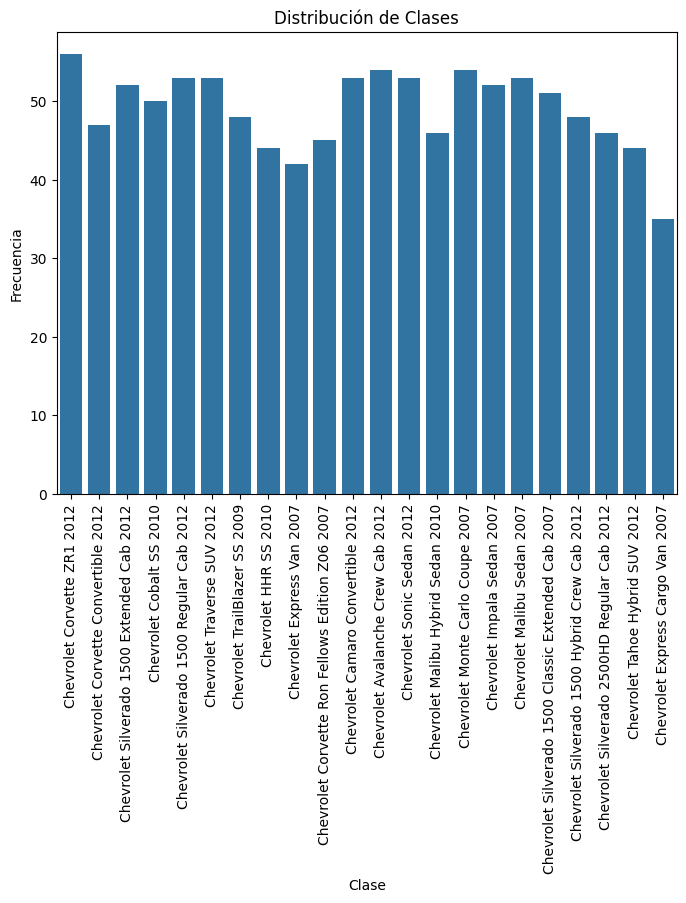

In [14]:
# ------------------------------------------------------------
# Distribución de clases
# ------------------------------------------------------------

#Este gráfico permite verificar si el dataset está balanceado o si existen clases minoritarias que puedan afectar el aprendizaje.

plt.figure(figsize=(8,6))
sns.countplot(x=df['class'])
plt.title('Distribución de Clases')
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.xticks(rotation=90)
plt.show()

### Análisis de bounding boxes

Se estudian propiedades de los bounding boxes, como ancho, alto y relación de aspecto. Esto permite caracterizar qué tan grandes son los objetos respecto a la imagen y qué tanta variabilidad existe en su forma.

Comprender esta distribución es útil para interpretar la dificultad de la tarea de localización.

In [15]:
# ------------------------------------------------------------
# Análisis geométrico de los bounding boxes
# ------------------------------------------------------------


# Calcula el ancho de cada 'bounding box' restando la coordenada x_min de x_max.
data_h_w['width'] = data_h_w['xmax'] - data_h_w['xmin'] 

# Calcula el alto de cada 'bounding box' restando la coordenada y_min de y_max.
data_h_w['height'] = data_h_w['ymax'] - data_h_w['ymin'] 

# Calcula el área de cada 'bounding box' multiplicando su ancho por su alto. Este valor es útil para el análisis del tamaño de los objetos.
data_h_w['area'] = data_h_w['width'] * data_h_w['height'] 

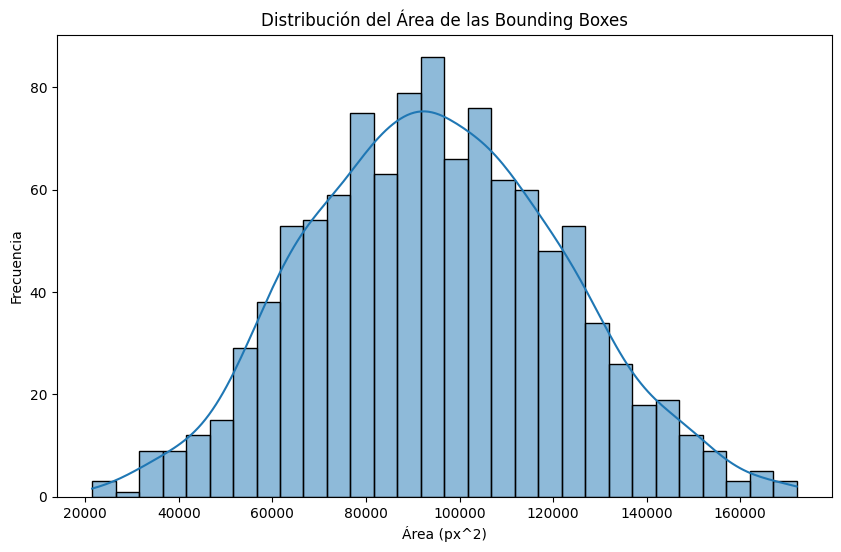

In [16]:
plt.figure(figsize=(10,6)) # Crea una figura de Matplotlib con un tamaño específico (ancho=10, alto=6 pulgadas).
sns.histplot(data_h_w['area'], bins=30, kde=True) # Crea un histograma de la columna 'area' con 30 divisiones (bins) y una estimación de densidad de kernel (KDE).
plt.title('Distribución del Área de las Bounding Boxes') # Establece el título del gráfico.
plt.xlabel('Área (px^2)') # Etiqueta el eje X como 'Área (px^2)'.
plt.ylabel('Frecuencia') # Etiqueta el eje Y como 'Frecuencia'.
plt.show() # Muestra el gráfico.

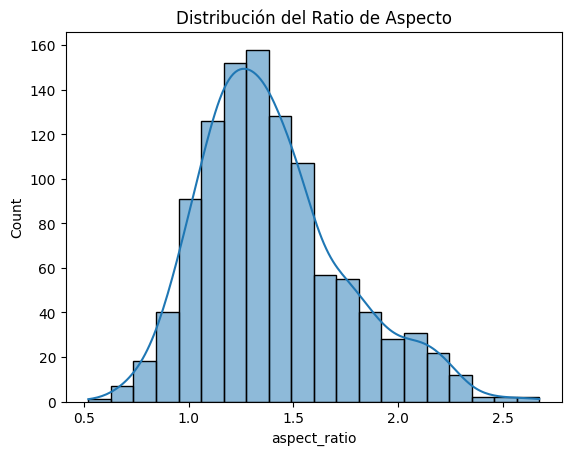

In [17]:
data_h_w['aspect_ratio'] = data_h_w['width'] / data_h_w['height'] # Calcula la relación de aspecto de cada 'bounding box' (ancho / alto).
sns.histplot(data_h_w['aspect_ratio'], bins=20, kde=True) # Crea un histograma de la relación de aspecto con 20 bins y una estimación de densidad de kernel.
plt.title("Distribución del Ratio de Aspecto") # Establece el título del gráfico.
plt.show() # Muestra el gráfico.

Durante el análisis exploratorio del dataset se evaluó la distribución de las coordenadas y propiedades geométricas de los bounding boxes, como el área y la relación de aspecto.

### Análisis de la distribución

Se observó que:

- El área de los bounding boxes sigue una distribución aproximadamente normal, sin evidencia de outliers severos que requieran transformación.
- La relación de aspecto (aspect ratio) muestra un comportamiento consistente, concentrándose en rangos que reflejan la forma natural de los vehículos.
En particular, el análisis del aspect ratio evidencia un sesgo esperado:  
los objetos (vehículos) presentan predominantemente una forma **rectangular horizontal**, lo cual es coherente con la estructura real de los carros.

In [18]:
# ------------------------------------------------------------
# Resumen estadístico de bboxes originales
# ------------------------------------------------------------

print("Resumen de bboxes originales:")
print(df[["xmin", "ymin", "xmax", "ymax"]].describe())

Resumen de bboxes originales:
              xmin         ymin         xmax         ymax
count  1079.000000  1079.000000  1079.000000  1079.000000
mean     31.555597    89.072062   385.849504   354.771590
std      24.215359    45.851856    26.357210    35.224160
min       0.260000     0.346667   241.996485   209.389755
25%      14.514783    58.066667   374.319691   332.108931
50%      25.350000    83.824000   393.250000   357.933333
75%      42.648125   118.064399   404.413683   382.235135
max     169.254902   270.185567   416.000000   416.000000


Los resultados revelan:

- **1079 imágenes** en total, todas de 416×416 píxeles.
- **1 imagen en escala de grises** detectada (se convierte automáticamente a RGB).
- **0 bounding boxes fuera de rango** — las anotaciones son consistentes.
- **22 clases** con distribución levemente desbalanceada: la clase con más muestras
  tiene 42 imágenes y la de menos tiene 26 (diferencia del 38%).


## 4.1. Normalización de bounding boxes

Los bounding boxes se normalizan respecto al ancho y alto de la imagen para expresar sus coordenadas en una escala comparable. Esta transformación facilita el entrenamiento del modelo de regresión, ya que reduce la dependencia de las dimensiones originales de cada imagen.

Los bboxes se normalizan dividiéndolos entre el ancho y alto de la imagen (416px).

Antes de normalizar: xmin media=31px, xmax media=385px.
Después de normalizar: xmin media=0.076, xmax media=0.928, todo en rango [0,1].

Esta escala compacta facilita la convergencia de la cabeza de regresión.

In [19]:
print("Bboxes originales")
print(df[["ymin", "ymax", "xmin", "xmax"]].describe())

Bboxes originales
              ymin         ymax         xmin         xmax
count  1079.000000  1079.000000  1079.000000  1079.000000
mean     89.072062   354.771590    31.555597   385.849504
std      45.851856    35.224160    24.215359    26.357210
min       0.346667   209.389755     0.260000   241.996485
25%      58.066667   332.108931    14.514783   374.319691
50%      83.824000   357.933333    25.350000   393.250000
75%     118.064399   382.235135    42.648125   404.413683
max     270.185567   416.000000   169.254902   416.000000


In [20]:
# ------------------------------------------------------------
# Normalizar coordenadas a rango [0, 1]
# ------------------------------------------------------------

df['xmin'] = df['xmin']/df['w']
df['xmax'] = df['xmax']/df['w']
df['ymin'] = df['ymin']/df['h']
df['ymax'] = df['ymax']/df['h']

In [21]:
print("Bboxes normalizados")
print(df[["ymin", "ymax", "xmin", "xmax"]].describe())

Bboxes normalizados
              ymin         ymax         xmin         xmax
count  1079.000000  1079.000000  1079.000000  1079.000000
mean      0.214116     0.852816     0.075855     0.927523
std       0.110221     0.084673     0.058210     0.063359
min       0.000833     0.503341     0.000625     0.581722
25%       0.139583     0.798339     0.034891     0.899807
50%       0.201500     0.860417     0.060938     0.945312
75%       0.283809     0.918834     0.102520     0.972148
max       0.649485     1.000000     0.406863     1.000000


## 5. Particionamiento en entrenamiento y validación

El dataset se divide en conjuntos de entrenamiento y validación para poder entrenar el modelo y evaluar su capacidad de generalización sobre datos no vistos. Esta separación es esencial para medir desempeño de forma honesta y evitar conclusiones optimistas por sobreajuste.

Se divide el dataset en:

- `train_df`
- `val_df`

Usando estratificación por clase.



Split estratificado 75/25: **809 imágenes train** y **270 imágenes validación**.

Las estadísticas de normalización y los pesos de clase se calculan exclusivamente sobre `train_df`, garantizando que no hay data leakage desde validación. Los pesos de clase compensan el desbalance: la clase 21 (26 muestras) recibe peso 1.398, la clase 0 (42 muestras) recibe peso 0.865.



In [22]:
# ------------------------------------------------------------
# Partición estratificada train / validation
# ------------------------------------------------------------

columns_f = ['filename', 'xmin','ymin','xmax','ymax','class_id','class','w','h'] # Define las columnas finales a utilizar del DataFrame.
df1 = df[columns_f].copy() # Crea una copia del DataFrame con solo las columnas seleccionadas.

train_df, val_df = train_test_split(
    df1, stratify=df1['class_id'], test_size=0.25, random_state=42 # Divide el DataFrame en conjuntos de entrenamiento (75%) y validación (25%), manteniendo la proporción de clases (estratificado).
)

print(train_df.shape) # Imprime las dimensiones del DataFrame de entrenamiento.
print(val_df.shape) # Imprime las dimensiones del DataFrame de validación.

(809, 9)
(270, 9)


In [23]:
# Pesos por clase para compensar desbalance
class_counts = train_df['class_id'].value_counts().sort_index()
class_weights = 1.0 / class_counts.values
class_weights = class_weights / class_weights.sum() * len(class_weights)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class counts:")
print(class_counts)
print("Class weights:")
print(class_weights)

Class counts:
class_id
0     42
1     35
2     39
3     37
4     40
5     40
6     36
7     33
8     32
9     34
10    40
11    40
12    40
13    34
14    40
15    39
16    40
17    38
18    36
19    35
20    33
21    26
Name: count, dtype: int64
Class weights:
tensor([0.8654, 1.0385, 0.9320, 0.9824, 0.9087, 0.9087, 1.0096, 1.1014, 1.1358,
        1.0690, 0.9087, 0.9087, 0.9087, 1.0690, 0.9087, 0.9320, 0.9087, 0.9565,
        1.0096, 1.0385, 1.1014, 1.3980], device='cuda:0')


In [24]:
train_df.head()

,filename,xmin,ymin,xmax,ymax,class_id,class,w,h
399,8769_train.jpg,0.117188,0.302500,0.942187,0.925000,7,Chevrolet HHR SS 2010,416,416
707,1999_train.jpg,0.073359,0.211340,0.961390,0.592784,14,Chevrolet Monte Carlo Coupe 2007,416,416
810,2123_train.jpg,0.059570,0.109375,0.951172,0.713542,16,Chevrolet Malibu Sedan 2007,416,416
1060,5075_train.jpg,0.051562,0.175000,0.946875,0.789583,21,Chevrolet Express Cargo Van 2007,416,416
568,5579_train.jpg,0.056667,0.240000,0.953333,0.915556,11,Chevrolet Avalanche Crew Cab 2012,416,416


## 6. Dataset personalizado

Se implementa una clase personalizada de PyTorch para cargar imágenes, etiquetas de clase y bounding boxes en el formato requerido por el modelo. Esta clase centraliza la lógica de lectura, preprocesamiento y transformación de los datos.

Esta clase:

- lee las imágenes,
- recupera clase y bounding box,
- aplica transformaciones,
- devuelve cada ejemplo en un formato compatible con PyTorch.

**Nota:** se corrigió la conversión de imágenes en escala de grises
para usar `cv2.COLOR_GRAY2RGB`.


In [25]:
# ============================================================
# Dataset y funciones de visualización 
# ============================================================

transform_func_inp_signature = ty.Dict[str, NDArray[np.float64]]
transform_func_signature = ty.Callable[
    [transform_func_inp_signature],
    transform_func_inp_signature
]

class CarsDataset(Dataset):
    """
    Dataset personalizado para clasificación + localización.
    """
    def __init__(
        self,
        df: pd.DataFrame,
        root_dir: str,
        labeled: bool = True,
        transform: ty.Optional[ty.List[transform_func_signature]] = None
    ) -> None:
        self.df = df
        self.root_dir = root_dir
        self.transform = transform
        self.labeled = labeled

    def __len__(self):
        return self.df.shape[0]

    # Cada muestra devuelve tres elementos principales: la imagen procesada, 
    #la etiqueta de clase y el bounding box normalizado. Esto permite entrenar simultáneamente las dos tareas del problema.
    def __getitem__(self, idx: int):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir, self.df.filename.iloc[idx])
        image = io.imread(img_name)

        if image.ndim == 2:
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        elif image.shape[2] == 4:
            image = image[:, :, :3]

        sample = {'image': image}

        if self.labeled:
            img_class = self.df.class_id.iloc[idx]
            img_bbox = self.df.iloc[idx, 1:5]

            img_bbox = np.array([img_bbox]).astype('float')
            img_class = np.array([img_class]).astype('int')

            sample.update({'bbox': img_bbox, 'class_id': img_class})

        if self.transform:
            sample = self.transform(sample)

        return sample

In [26]:
# ============================================================
# Funciones de visualización 
# ============================================================

def draw_bbox(img, bbox, color):
    xmin, ymin, xmax, ymax = bbox
    img = cv2.rectangle(img, (xmin, ymin), (xmax, ymax), color, 2)
    return img

def normalize_bbox(bbox, factor: int = 416):
    return list(map(lambda x: int(x * factor), bbox))

def draw_bboxes(imgs, bboxes, colors):
    for i, (img, bbox, color) in enumerate(zip(imgs, bboxes, colors)):
        imgs[i] = draw_bbox(img, bbox, color)
    return imgs

def draw_classes(imgs, classes, colors, origin, offset: int = 5, prefix: str = ''):
    for i, (img, class_id, color) in enumerate(zip(imgs, classes, colors)):
        if type(class_id) == list:
            name_class_ = id2obj[classes[i]]
        else:
            name_class_ = id2obj[classes[i][0]]

        imgs[i] = cv2.putText(
            img,
            f'{prefix}{name_class_}',
            origin,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            color,
            1,
            cv2.LINE_AA
        )
    return imgs

def draw_predictions(imgs, classes, bboxes, colors, origin):
    assert all(len(x) > 0 for x in [imgs, classes, bboxes, colors])

    if len(colors) == 1:
        colors = [colors[0] for _ in imgs]

    imgs = draw_bboxes(imgs, bboxes, colors)
    imgs = draw_classes(imgs, classes, colors, origin)
    return imgs

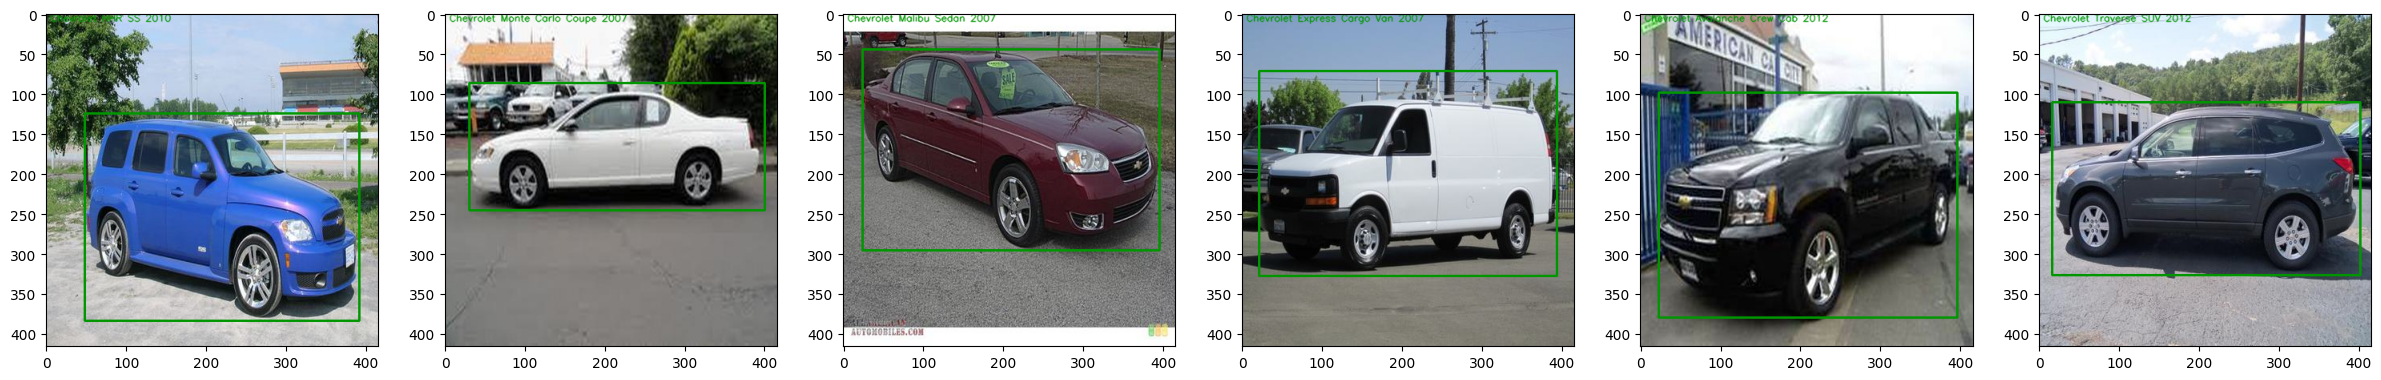

In [27]:
# ============================================================
# Visualización de muestra
# ============================================================


train_root_dir = osp.join(DATA_DIR, "cars/cars_resize")
train_ds = CarsDataset(train_df, root_dir=train_root_dir)

num_imgs = 6
start_idx = 0

samples = [train_ds[i] for i in range(start_idx, num_imgs)]

imgs = [s['image'] for s in samples]
bboxes = [normalize_bbox(s['bbox'].squeeze()) for s in samples]
classes = [s['class_id'] for s in samples]

imgs = draw_predictions(imgs, classes, bboxes, [(0, 150, 0)], (5, 10))

fig = plt.figure(figsize=(30, num_imgs))
for i, img in enumerate(imgs):
    fig.add_subplot(1, num_imgs, i+1)
    plt.imshow(img)
plt.show()

In [28]:
# ============================================================
# Normalización de imágenes
# ============================================================

train_ds = CarsDataset(train_df, root_dir=train_root_dir)

means = np.zeros(3)
stds = np.zeros(3)
n_images = 0

for x in train_ds:
    img = x['image']
    n_images += 1

    for channel in range(3):
        channel_pixels = img[..., channel]
        means[channel] += np.mean(channel_pixels)
        stds[channel] += np.std(channel_pixels)

means /= n_images
stds /= n_images

print(means)
print(stds)

[123.14417523 121.13234936 120.28185433]
[67.64966374 67.53653124 68.97018524]


## 7. Transformaciones y augmentations

En esta sección se definen las transformaciones aplicadas a las imágenes antes de alimentar el modelo. Estas incluyen transformaciones base para normalización y redimensionamiento, así como técnicas de aumento de datos para incrementar la diversidad visual del conjunto de entrenamiento.

Aquí se definen:

- conversión a tensor,
- normalización,
- wrapper para Albumentations
- aumentación offline para balancear clases.



Se definen dos normalizaciones distintas:

- **CNN propio**: stats del dataset (means≈0.483, stds≈0.265).
  
- **EfficientNet y ConvNeXt**: stats ImageNet (means=0.485/0.456/0.406, stds=0.229/0.224/0.225).

Esta separación es esencial: los modelos preentrenados en ImageNet esperan exactamente esas estadísticas en sus primeras capas congeladas.


A recommended library to do image augmentation is https://albumentations.ai/docs/examples/pytorch_classification/


In [29]:
# ============================================================
# Definicion de clases de transformacion
# ============================================================

class ToTensor(object):
    """Convert ndarrays in sample to Tensors."""
    def __call__(self, sample):
        image = sample['image']
        # Convierte HWC a CHW y normaliza a float
        image = image.transpose((2, 0, 1)).astype(np.float32) / 255.0
        sample['image'] = torch.from_numpy(image)
        if 'bbox' in sample:
            sample['bbox']     = torch.from_numpy(sample['bbox']).float()
        if 'class_id' in sample:
            sample['class_id'] = torch.from_numpy(sample['class_id']).long()
        return sample

class Normalizer(object):
    """Normaliza los valores de pixeles usando media y desviacion estandar."""
    def __init__(self, means, stds):
        self.means = means
        self.stds  = stds

    def __call__(self, sample):
        image = sample['image'].float()
        for c in range(3):
            image[c] = (image[c] - self.means[c]) / (self.stds[c] + 1e-6)
        sample['image'] = image
        return sample

class AlbumentationsWrapper:
    """
    Envuelve transformaciones de Albumentations para el pipeline de CarsDataset.
    """
    def __init__(self, transform):
        self.transform = transform

    def __call__(self, sample):
        image = sample['image']
        result = self.transform(image=image)
        sample['image'] = result['image']
        return sample

# ── Transforms ───────────────────────────────────────────────
# ── Transforms para CNN personalizado (stats del dataset) ────
common_transforms = [
    ToTensor(),
    Normalizer(means=means/255.0, stds=stds/255.0)
]

train_transforms = torchvision.transforms.Compose(
    [] + common_transforms
    # AlbumentationsWrapper comentado — augmentation ya aplicado offline en data_final
    # Aplicar online tambien causaria doble augmentation y degradaria el modelo
)

eval_transforms = torchvision.transforms.Compose(common_transforms)

# ── Transforms para modelos preentrenados (stats ImageNet) ───
# EfficientNet y ConvNeXt fueron preentrenados con estas estadísticas
# Usar otras stats degrada los features de los bloques congelados
IMAGENET_MEANS = np.array([0.485, 0.456, 0.406])
IMAGENET_STDS  = np.array([0.229, 0.224, 0.225])

imagenet_transforms = torchvision.transforms.Compose([
    ToTensor(),
    Normalizer(means=IMAGENET_MEANS, stds=IMAGENET_STDS)
])

print(f"Stats dataset  — means: {(means/255.0).round(3)}, stds: {(stds/255.0).round(3)}")
print(f"Stats ImageNet — means: {IMAGENET_MEANS}, stds: {IMAGENET_STDS}") 

Stats dataset  — means: [0.483 0.475 0.472], stds: [0.265 0.265 0.27 ]
Stats ImageNet — means: [0.485 0.456 0.406], stds: [0.229 0.224 0.225]


## 7.1 Aumentación offline y balanceo de clases

La aumentación offline genera nuevas muestras a partir de clases existentes, lo que ayuda a mitigar el desbalance del dataset y a exponer al modelo a variaciones visuales adicionales. Esto puede ser especialmente útil cuando algunas clases tienen pocas observaciones.

Las transformaciones utilizadas buscan simular condiciones realistas de variación visual:

- **HorizontalFlip**: útil porque el vehículo puede aparecer orientado hacia diferentes lados.
- **Rotate / Affine**: introduce pequeñas variaciones geométricas.
- **Brightness / Contrast / Color**: simula cambios de iluminación y ambiente.
- **Blur**: fortalece robustez frente a imágenes menos nítidas.
- **CoarseDropout**: evita que el modelo dependa solo de una región específica.

Estas técnicas son apropiadas siempre que se mantenga la coherencia entre la imagen transformada y el bounding box.

Las transformaciones se aplican de forma probabilística, lo que permite generar diferentes variaciones de una misma imagen a lo largo del entrenamiento sin duplicar explícitamente el dataset.


Se generan imágenes sintéticas hasta alcanzar 63 muestras por clase (1.5× el máximo original de 42). El dataset train pasa de 809 a **1375 muestras** (+70%). Todas las clases quedan exactamente balanceadas en 63 imágenes. La restricción `min(needed, count)` garantiza que ninguna clase genera más imágenes sintéticas que originales tiene, evitando memorización por repetición.

In [30]:
# ============================================================
# Transformaciones Albumentations
# ============================================================

import shutil
import cv2
import os
import pandas as pd


# 1. Definir augmentation offline
train_data_augmentations = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.ShiftScaleRotate(
        shift_limit=0.03,
        scale_limit=0.05,
        rotate_limit=8,
        border_mode=cv2.BORDER_CONSTANT,
        p=0.45
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.3
    ),

    A.HueSaturationValue(
        hue_shift_limit=6,
        sat_shift_limit=10,
        val_shift_limit=6,
        p=0.2
    ),

    A.GaussianBlur(blur_limit=(3, 3), p=0.08),

    A.Resize(height=416, width=416, p=1)
],
bbox_params=A.BboxParams(
    format='albumentations',
    label_fields=['class_labels'],
    min_visibility=0.5
))

dataaug_transforms = torchvision.transforms.Compose(
    [
        AlbumentationsWrapper(train_data_augmentations)
    ]
)

# 2. Recrear carpeta de salida
if os.path.exists('data_final'):
    shutil.rmtree('data_final')

os.mkdir('data_final')

balanced_rows = []

# 3. Copiar imagenes originales y agregarlas al dataframe final
for _, row in train_df.iterrows():
    src = os.path.join(train_root_dir, row['filename'])
    dst = os.path.join('data_final', row['filename'])
    img = cv2.imread(src)
    cv2.imwrite(dst, img)
    balanced_rows.append(row.to_dict())

# 4. Contar clases
class_counts = train_df['class'].value_counts()
target_count  = int(class_counts.max() * 1.5)
print("Conteo original:")
print(class_counts)
print("Objetivo por clase:", target_count)

# 5. Definir indice inicial para nuevas imagenes
last_index = max(
    int(x.replace('_train', '').replace('.jpg', ''))
    for x in train_df['filename']
)
index = last_index + 1

# 6. Generar imagenes nuevas solo para clases minoritarias
for class_name, count in class_counts.items():
    needed = target_count - count
    if needed <= 0:
        continue
    needed = min(needed, count)  # No generar más sintéticas que originales # HHBL 
    # Las clases con más de 40 imágenes se ignoran correctamente, pero las clases pequeñas reciben muchas imágenes
    # sintéticas repetidas de pocas originales — una clase con 5 imágenes generaría 35 sintéticas a partir de esas mismas 5, 
    # causando memorización

    class_rows = train_df[train_df['class'] == class_name].reset_index(drop=True)

    generated = 0
    while generated < needed:
        row = class_rows.iloc[generated % len(class_rows)]

        img_path = os.path.join(train_root_dir, row['filename'])
        image    = cv2.imread(img_path)
        image    = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        bbox = [row['xmin'], row['ymin'], row['xmax'], row['ymax']]

        transformed = train_data_augmentations(
            image=image,
            bboxes=[bbox],
            class_labels=[row['class_id']]
        )

        if len(transformed['bboxes']) == 0:
            continue

        aug_img  = transformed['image']
        aug_bbox = transformed['bboxes'][0]

        new_filename = f"{index}_train.jpg"
        index += 1

        aug_img_bgr = cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR)
        cv2.imwrite(os.path.join('data_final', new_filename), aug_img_bgr)

        new_row             = row.to_dict()
        new_row['filename'] = new_filename
        new_row['xmin']     = aug_bbox[0]
        new_row['ymin']     = aug_bbox[1]
        new_row['xmax']     = aug_bbox[2]
        new_row['ymax']     = aug_bbox[3]

        balanced_rows.append(new_row)
        generated += 1

# 7. Crear dataframe final balanceado
dataframe_with_dataaugmentation = pd.DataFrame(balanced_rows)
print("\nConteo balanceado:")
print(dataframe_with_dataaugmentation['class'].value_counts())
dataframe_with_dataaugmentation.head() #HHBL

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Conteo original:
class
Chevrolet Corvette ZR1 2012                           42
Chevrolet Monte Carlo Coupe 2007                      40
Chevrolet Traverse SUV 2012                           40
Chevrolet Avalanche Crew Cab 2012                     40
Chevrolet Sonic Sedan 2012                            40
Chevrolet Malibu Sedan 2007                           40
Chevrolet Camaro Convertible 2012                     40
Chevrolet Silverado 1500 Regular Cab 2012             40
Chevrolet Silverado 1500 Extended Cab 2012            39
Chevrolet Impala Sedan 2007                           39
Chevrolet Silverado 1500 Classic Extended Cab 2007    38
Chevrolet Cobalt SS 2010                              37
Chevrolet Silverado 1500 Hybrid Crew Cab 2012         36
Chevrolet TrailBlazer SS 2009                         36
Chevrolet Silverado 2500HD Regular Cab 2012           35
Chevrolet Corvette Convertible 2012                   35
Chevrolet Malibu Hybrid Sedan 2010                    34
Chevrole

,filename,xmin,ymin,xmax,ymax,class_id,class,w,h
0,8769_train.jpg,0.117188,0.302500,0.942187,0.925000,7,Chevrolet HHR SS 2010,416,416
1,1999_train.jpg,0.073359,0.211340,0.961390,0.592784,14,Chevrolet Monte Carlo Coupe 2007,416,416
2,2123_train.jpg,0.059570,0.109375,0.951172,0.713542,16,Chevrolet Malibu Sedan 2007,416,416
3,5075_train.jpg,0.051562,0.175000,0.946875,0.789583,21,Chevrolet Express Cargo Van 2007,416,416
4,5579_train.jpg,0.056667,0.240000,0.953333,0.915556,11,Chevrolet Avalanche Crew Cab 2012,416,416


In [31]:
dataframe_with_dataaugmentation.tail()

,filename,xmin,ymin,xmax,ymax,class_id,class,w,h
1370,10266_train.jpg,0.049968,0.040427,0.999460,0.936811,21,Chevrolet Express Cargo Van 2007,416,416
1371,10267_train.jpg,0.115913,0.159593,0.905001,0.812954,21,Chevrolet Express Cargo Van 2007,416,416
1372,10268_train.jpg,0.038617,0.075869,1.000000,0.735795,21,Chevrolet Express Cargo Van 2007,416,416
1373,10269_train.jpg,0.051562,0.197917,0.857812,0.891667,21,Chevrolet Express Cargo Van 2007,416,416
1374,10270_train.jpg,0.029687,0.169014,0.975000,0.931925,21,Chevrolet Express Cargo Van 2007,416,416


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


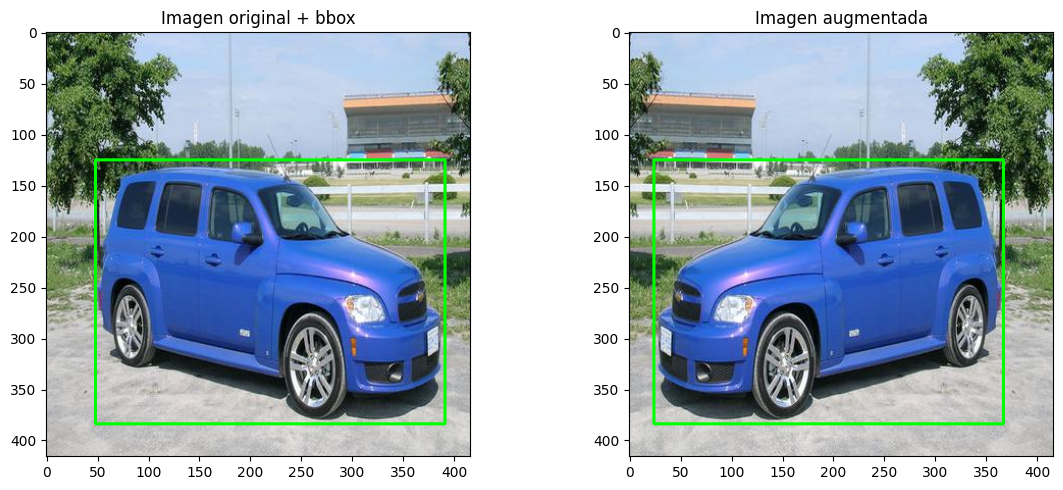

In [106]:
# ============================================================
# Visualización de una imagen transformada
# ============================================================

def denormalize_img(tensor_img, means, stds):
    """
    Revierte la normalización (pixel - mean) / std donde pixel ∈ [0, 255].
    Devuelve imagen uint8 (H, W, C) lista para matplotlib/OpenCV.
    """
    if hasattr(tensor_img, 'numpy'):
        img = tensor_img.numpy().copy()
    else:
        img = tensor_img.copy()

    for c in range(3):
        img[c] = img[c] * stds[c] + means[c]

    img = img.transpose(1, 2, 0)
    img = img.clip(0, 255).astype(np.uint8)
    return np.ascontiguousarray(img)


# ── Obtener muestra ───────────────────────────────────────────
# Usamos p=1.0 en todas las transformaciones para garantizar
# que la imagen augmentada sea visiblemente distinta a la original.
# En el entrenamiento real se usan las probabilidades normales.
aug_para_viz = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.ShiftScaleRotate(
        shift_limit=0.03,
        scale_limit=0.05,
        rotate_limit=8,
        border_mode=cv2.BORDER_CONSTANT,
        p=0.45
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.3
    ),

    A.HueSaturationValue(
        hue_shift_limit=6,
        sat_shift_limit=10,
        val_shift_limit=6,
        p=0.2
    ),

    A.GaussianBlur(blur_limit=(3, 3), p=0.08),

    A.Resize(height=416, width=416, p=1)
],
bbox_params=A.BboxParams(
    format='albumentations',
    label_fields=[],
    min_visibility=0.5
))

train_ds     = CarsDataset(train_df, root_dir=train_root_dir)
x            = next(iter(train_ds))

original_img = np.ascontiguousarray(x['image'].copy())
orig_bbox    = np.array(x['bbox']).squeeze()

# Aplicar augmentation directamente sobre numpy
result    = aug_para_viz(image=original_img, bboxes=[orig_bbox.tolist()])
aug_img   = result['image']
aug_bboxes = result['bboxes']

# Dibujar bbox en original
original_with_bbox = draw_bbox(
    original_img.copy(),
    normalize_bbox(orig_bbox),
    (0, 255, 0)
)

# Dibujar bbox en augmentada
if len(aug_bboxes) > 0:
    aug_bbox      = np.array(aug_bboxes[0])
    aug_with_bbox = draw_bbox(
        aug_img.copy(),
        normalize_bbox(aug_bbox),
        (0, 255, 0)
    )
else:
    aug_with_bbox = aug_img.copy()
    print("Bbox descartado por min_visibility en esta muestra, intenta con otra.")

# ── Mostrar ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original_with_bbox)
axes[0].set_title('Imagen original + bbox')
axes[1].imshow(aug_with_bbox)
axes[1].set_title('Imagen augmentada')
plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# Dataloader de prueba
# ============================================================

#train_ds = CarsDataset(train_df, root_dir=train_root_dir, transform=train_transforms)
train_ds = CarsDataset(dataframe_with_dataaugmentation, root_dir='data_final', transform=train_transforms) # Crea una instancia de CarsDataset usando el DataFrame que incluye las imágenes aumentadas y las transformaciones de entrenamiento. Se especifica 'data_final' como el directorio raíz donde se encuentran ahora todas las imágenes (originales y aumentadas).
train_data = torch.utils.data.DataLoader(train_ds, batch_size=16) # Crea un DataLoader a partir del train_ds. Este DataLoader se encargará de cargar los datos en lotes (batch_size=16) para el entrenamiento.

for x in train_data: # Inicia un bucle para iterar sobre el DataLoader. Este bucle se ejecutará una vez para obtener el primer lote.
    print(x['image'].size()) # Imprime el tamaño del tensor de imágenes del primer lote, lo que ayuda a verificar que los datos se están cargando correctamente (ej., [batch_size, canales, alto, ancho]).
    break # Rompe el bucle después de procesar el primer lote, ya que el objetivo es solo mostrar el tamaño de un lote de ejemplo.


torch.Size([16, 3, 416, 416])


In [104]:
dataframe_with_dataaugmentation.count()

filename    1375
xmin        1375
ymin        1375
xmax        1375
ymax        1375
class_id    1375
class       1375
w           1375
h           1375
dtype: int64

## 8. Modelos

Se comparan tres alternativas de backbone:

1. un **CNN personalizado** entrenado desde cero,
2. **EfficientNet-B2** preentrenado,
3. **ConvNeXt-Tiny** preentrenado.

Todos los modelos se integran en una arquitectura multitarea con una cabeza de clasificación y una cabeza de regresión.

## 8.1 Modelo 1 - CNN personalizado

Se diseñó un modelo de red neuronal convolucional desde cero con el objetivo de extraer características visuales relevantes de los vehículos. A diferencia de los modelos preentrenados, este enfoque permite evaluar la capacidad del modelo para aprender representaciones directamente a partir de los datos disponibles.

### Arquitectura
 
Backbone de **5 bloques convolucionales** con doble conv por bloque:
- Bloque 1: 3→64 filtros, 416×416 → 208×208
- Bloque 2: 64→128 filtros, 208×208 → 104×104
- Bloque 3: 128→256 filtros, 104×104 → 52×52
- Bloque 4: 256→512 filtros, 52×52 → 26×26
- Bloque 5: 512→512 filtros, 26×26 → 13×13

Seguido de AdaptiveAvgPool2d → **512 features**. BatchNorm y ReLU en cada capa,
dropout=0.3 en el pooling global. Inicialización Xavier para todas las capas.

In [34]:
# ------------------------------------------------------------
# Backbone + clasificación + regresión
# ------------------------------------------------------------

class CustomCNNBackbone(nn.Module):
    """
    Backbone CNN personalizado desde cero.
    5 bloques convolucionales con doble conv por bloque.
    Produce 512 features via AdaptiveAvgPool2d.
    """
    def __init__(self, dropout_rate=0.4):
        super().__init__()

        self.features = nn.Sequential(
            # Bloque 1: 3→64, 416×416 → 208×208
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),

            # Bloque 2: 64→128, 208×208 → 104×104
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),

            # Bloque 3: 128→256, 104×104 → 52×52
            nn.Conv2d(128, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2),

            # Bloque 4: 256→512, 52×52 → 26×26
            nn.Conv2d(256, 512, 3, padding=1, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.MaxPool2d(2),

            # Bloque 5: 512→512, 26×26 → 13×13
            nn.Conv2d(512, 512, 3, padding=1, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = self.features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return x  # → 512 features 

In [35]:
def initialize_weights(model):
    """
    Inicialización de pesos con Xavier para todas las capas:
    - Conv2d:      Xavier Normal
    - BatchNorm2d: weight=1, bias=0
    - Linear:      Xavier Normal
    """
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_normal_(m.weight)
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.constant_(m.weight, 1)
            nn.init.constant_(m.bias, 0)
    print("✓ Pesos inicializados con Xavier Normal")

In [36]:
class ModelCNN(nn.Module):
    def __init__(self, n_classes=22):
        super().__init__()
        self.backbone = CustomCNNBackbone(dropout_rate=0.3).to(device)
        self.input_shape = (3, 416, 416)
        self.feat_dim = 512  # backbone produce 512 features

        self.cls_head = nn.Linear(self.feat_dim, n_classes)
        self.reg_head = nn.Sequential(
            nn.Linear(self.feat_dim, 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.backbone(x)
        cls_logits = self.cls_head(features)
        pred_bbox = self.reg_head(features)
        return {'class_id': cls_logits, 'bbox': pred_bbox} 

In [37]:
# ── Arquitectura del CNN personalizado ───────────────────────
_tmp = ModelCNN(n_classes=22).to(device)
print("=" * 60)
print("ARQUITECTURA CNN PERSONALIZADO")
print("=" * 60)
summary(_tmp, input_size=(3, 416, 416))
del _tmp
torch.cuda.empty_cache() 

ARQUITECTURA CNN PERSONALIZADO
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 416, 416]           1,728
       BatchNorm2d-2         [-1, 64, 416, 416]             128
              ReLU-3         [-1, 64, 416, 416]               0
            Conv2d-4         [-1, 64, 416, 416]          36,864
       BatchNorm2d-5         [-1, 64, 416, 416]             128
              ReLU-6         [-1, 64, 416, 416]               0
         MaxPool2d-7         [-1, 64, 208, 208]               0
            Conv2d-8        [-1, 128, 208, 208]          73,728
       BatchNorm2d-9        [-1, 128, 208, 208]             256
             ReLU-10        [-1, 128, 208, 208]               0
           Conv2d-11        [-1, 128, 208, 208]         147,456
      BatchNorm2d-12        [-1, 128, 208, 208]             256
             ReLU-13        [-1, 128, 208, 208]               0
        

### Uso de transfer learning

Se utilizaron modelos preentrenados como EfficientNet y ConvNeXt para aprovechar representaciones visuales aprendidas previamente en ImageNet.

El transfer learning permite:

- acelerar la convergencia,
- mejorar la generalización,
- y reducir la necesidad de grandes volúmenes de datos.

Esto es especialmente útil en este problema, donde el dataset no es extremadamente grande.

## 8.2 Modelo 2 - EfficientNet-B2


EfficientNet-B2 se utiliza como backbone preentrenado por su buen balance entre eficiencia computacional y capacidad de representación. 

Backbone preentrenado en ImageNet. Produce **1408 features**.

Los últimos 2 bloques se descongelan para fine-tuning; el resto permanece congelado para preservar las representaciones generales aprendidas en ImageNet. Se añade LayerNorm y Dropout(0.2) antes de las cabezas.

In [38]:
# ------------------------------------------------------------
# Backbone + clasificación + regresión
# ------------------------------------------------------------

from torchvision.models import efficientnet_b2, EfficientNet_B2_Weights

class FeatureExtractor(nn.Module):
    """
    Backbone EfficientNet-B2.
    Produce 1408 features.
    """
    def __init__(self):
        super().__init__()
        base = efficientnet_b2(weights=EfficientNet_B2_Weights.IMAGENET1K_V1)

        self.features = base.features
        self.pool = base.avgpool
        self.flatten = nn.Flatten()
        self.bn = nn.LayerNorm(1408)
        self.dropout = nn.Dropout(0.2)

        # Congelar todo excepto los últimos 2 bloques
        for block in list(self.features.children())[:-2]:
            for p in block.parameters():
                p.requires_grad = False

    def forward(self, x):
        out = self.features(x)
        out = self.pool(out)
        out = self.flatten(out)
        out = self.bn(out)
        out = self.dropout(out)
        return out


# %%
class ModelEfficientNet(nn.Module):
    def __init__(self, input_shape=(3, 416, 416)):
        super().__init__()

        self.input_shape = input_shape
        self.backbone = FeatureExtractor()
        self.feat_dim = 1408

        self.cls_head = None
        self.reg_head = None

    def forward(self, x):
        features = self.backbone(x)

        if self.cls_head is None or self.reg_head is None:
            raise ValueError("Debes definir cls_head y reg_head antes de entrenar.")

        cls_logits = self.cls_head(features)
        pred_bbox = self.reg_head(features)

        return {
            'class_id': cls_logits,
            'bbox': pred_bbox
        }

## 8.3 Modelo 3 - ConvNeXt-Tiny

ConvNeXt-Tiny representa una arquitectura moderna basada en convoluciones, diseñada para incorporar mejoras recientes en visión por computador.


Backbone preentrenado en ImageNet. Produce **768 features**.
Los últimos 2 bloques se descongelan. Diseño moderno con depthwise convolutions y arquitectura inspirada en transformers, lo que le da mayor capacidad de representación por parámetro comparado con EfficientNet.

In [39]:
# ------------------------------------------------------------
# Backbone + clasificación + regresión
# ------------------------------------------------------------

from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

class ConvNeXtBackbone(nn.Module):
    """
    Backbone preentrenado ConvNeXt-Tiny.
    Produce 768 features.
    """
    def __init__(self):
        super().__init__()
        base = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)

        self.features = base.features
        self.pool = base.avgpool
        self.flatten = nn.Flatten()
        self.bn = nn.LayerNorm(768)
        self.dropout = nn.Dropout(0.3)

        # Congelar todo excepto los últimos bloques
        children = list(self.features.children())
        for block in children[:-2]:
            for p in block.parameters():
                p.requires_grad = False

    def forward(self, x):
        out = self.features(x)
        out = self.pool(out)
        out = self.flatten(out)
        out = self.bn(out)
        out = self.dropout(out)
        return out


# %%
class ModelConvNeXt(nn.Module):
    def __init__(self):
        super().__init__()

        self.input_shape = (3, 416, 416)
        self.backbone = ConvNeXtBackbone()
        self.feat_dim = 768

        self.cls_head = None
        self.reg_head = None

    def forward(self, x):
        features = self.backbone(x)

        if self.cls_head is None or self.reg_head is None:
            raise ValueError("Debes definir cls_head y reg_head antes de entrenar.")

        cls_logits = self.cls_head(features)
        pred_bbox = self.reg_head(features)

        return {
            'class_id': cls_logits,
            'bbox': pred_bbox
        }

## 9. Métricas y función de pérdida multitarea

La pérdida final combina:

- `cross_entropy` para clasificación,
- `smooth_l1` + `GIoU` para regresión. 

La evaluación del modelo se realiza usando métricas específicas para cada tarea:

- `Accuracy` para clasificación,
- `Dice` para localización.


El coeficiente Dice mide el nivel de solapamiento entre el bounding box real y el predicho. Valores más altos indican mejor localización del objeto.

SmoothL1 ayuda a estabilizar la regresión de coordenadas, mientras que GIoU aporta una medida más geométrica del error de localización.


In [40]:
def dice_coefficient(y_true, y_pred, eps=1e-6):
    y_true = y_true.reshape(-1, 4)
    y_pred = y_pred.reshape(-1, 4)

    inter_xmin = torch.max(y_true[:, 0], y_pred[:, 0])
    inter_ymin = torch.max(y_true[:, 1], y_pred[:, 1])
    inter_xmax = torch.min(y_true[:, 2], y_pred[:, 2])
    inter_ymax = torch.min(y_true[:, 3], y_pred[:, 3])

    inter_w = (inter_xmax - inter_xmin).clamp(min=0)
    inter_h = (inter_ymax - inter_ymin).clamp(min=0)
    inter_area = inter_w * inter_h

    area_true = ((y_true[:, 2] - y_true[:, 0]) *
                 (y_true[:, 3] - y_true[:, 1])).clamp(min=0)
    area_pred = ((y_pred[:, 2] - y_pred[:, 0]) *
                 (y_pred[:, 3] - y_pred[:, 1])).clamp(min=0)

    dice = (2 * inter_area + eps) / (area_true + area_pred + eps)
    return dice.mean()


def accuracy(y_true, y_pred):
    preds = torch.argmax(y_pred, dim=-1)
    y_true = y_true.reshape(-1)
    return (preds == y_true).float().mean()


def iou(y_true, y_pred):
    y_true = y_true.reshape(-1, 4)
    y_pred = y_pred.reshape(-1, 4)
    pairwise_iou = torchvision.ops.box_iou(y_true, y_pred)
    return torch.trace(pairwise_iou) / pairwise_iou.size()[0]


def giou_loss(pred, target, eps=1e-6):
    pred = pred.reshape(-1, 4)
    target = target.reshape(-1, 4)

    inter_x1 = torch.max(pred[:, 0], target[:, 0])
    inter_y1 = torch.max(pred[:, 1], target[:, 1])
    inter_x2 = torch.min(pred[:, 2], target[:, 2])
    inter_y2 = torch.min(pred[:, 3], target[:, 3])

    inter_w = (inter_x2 - inter_x1).clamp(0)
    inter_h = (inter_y2 - inter_y1).clamp(0)
    inter_area = inter_w * inter_h

    area_pred = ((pred[:, 2] - pred[:, 0]).clamp(0) *
                 (pred[:, 3] - pred[:, 1]).clamp(0))
    area_target = ((target[:, 2] - target[:, 0]).clamp(0) *
                   (target[:, 3] - target[:, 1]).clamp(0))

    union_area = area_pred + area_target - inter_area + eps
    iou_val = inter_area / union_area

    enc_x1 = torch.min(pred[:, 0], target[:, 0])
    enc_y1 = torch.min(pred[:, 1], target[:, 1])
    enc_x2 = torch.max(pred[:, 2], target[:, 2])
    enc_y2 = torch.max(pred[:, 3], target[:, 3])

    enc_area = ((enc_x2 - enc_x1).clamp(0) *
                (enc_y2 - enc_y1).clamp(0)) + eps

    giou = iou_val - (enc_area - union_area) / enc_area
    return (1 - giou).mean()


def combined_loss(y_true, y_pred, alpha=0.20):
    cls_true = y_true['class_id'].reshape(-1).long()
    cls_pred = y_pred['class_id']

    cls_loss = F.cross_entropy(
        cls_pred,
        cls_true,
        weight=class_weights,
        label_smoothing=0.03
    )

    reg_true = y_true['bbox'].reshape(-1, 4).float()
    reg_pred = y_pred['bbox'].reshape(-1, 4).float()

    smooth_l1 = F.smooth_l1_loss(reg_pred, reg_true)
    g_iou = giou_loss(reg_pred, reg_true)

    reg_loss = 0.3 * smooth_l1 + 0.7 * g_iou
    total = (1 - alpha) * cls_loss + alpha * reg_loss

    return {
        'loss': total,
        'cls_loss': cls_loss,
        'reg_loss': reg_loss
    }


loss_fn = combined_loss

## 10. Funciones de entrenamiento y evaluación

Se implementa una función general de entrenamiento/evaluación por época que calcula pérdidas y métricas para ambas tareas. Esto permite reutilizar la misma lógica tanto en entrenamiento como en validación y facilita la comparación entre modelos.

In [41]:
def run_epoch(model, loader, optimizer, alpha, device, train=True):
    model.train() if train else model.eval()

    total_loss     = 0.0
    total_cls_loss = 0.0
    total_reg_loss = 0.0
    total_dice     = 0.0
    total_acc      = 0.0
    n_batches      = 0

    ctx = torch.enable_grad() if train else torch.no_grad()

    with ctx:
        for batch in loader:
            imgs = batch['image'].float().to(device)

            labels = {
                'class_id': batch['class_id'].to(device),
                'bbox': batch['bbox'].float().to(device),
            }

            preds = model(imgs)
            losses = combined_loss(labels, preds, alpha=alpha)

            if train:
                optimizer.zero_grad()
                losses['loss'].backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += losses['loss'].item()
            total_cls_loss += losses['cls_loss'].item()
            total_reg_loss += losses['reg_loss'].item()
            total_dice += dice_coefficient(labels['bbox'], preds['bbox']).item()
            total_acc += accuracy(labels['class_id'], preds['class_id']).item()
            n_batches += 1

    epoch_metrics = {
        'loss': total_loss / n_batches,
        'cls_loss': total_cls_loss / n_batches,
        'reg_loss': total_reg_loss / n_batches,
        'dice': total_dice / n_batches,
        'accuracy': total_acc / n_batches,
    }

    return epoch_metrics

def printer(logs):
    # Solo imprime cada 10 iteraciones
    if logs['iters'] % 10 != 0:
        return

    # Imprime el número de iteración
    print(f"Iter {logs['iters']:03d} | ", end='')

    # Recorre todas las métricas guardadas en logs
    for k, v in logs.items():
        if k == 'iters':
            continue

        # Solo imprime valores numéricos tipo float
        if isinstance(v, float):
            print(f"{k}={round(v, 4)}", end='  ')
    print()


def evaluate(logs, labels, preds, eval_set, metrics, losses=None):
    # Si recibe losses, las agrega al diccionario de logs
    if losses is not None:
        for loss_name, loss_value in losses.items():
            logs[f'{eval_set}_{loss_name}'] = loss_value.item() if hasattr(loss_value, 'item') else loss_value

    # Recorre cada tarea: bbox y class_id
    for task_name, label in labels.items():

        # Para cada tarea, calcula las métricas definidas
        for metric_name, metric in metrics[task_name]:
            value = metric(label, preds[task_name])

            # Guarda la métrica en logs con prefijo del conjunto
            # por ejemplo: train_accuracy o val_iou
            logs[f'{eval_set}_{metric_name}'] = value.item() if hasattr(value, 'item') else value

    return logs



In [42]:
# ============================================================
# Early stopping
# ============================================================


class EarlyStoppingScore:
    def __init__(self, patience=8, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = -float('inf')
        self.counter = 0
        self.best_weights = None

    def step(self, score, model):
        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter = 0
            self.best_weights = copy.deepcopy(model.state_dict())
            print(f"  ✓ Mejor modelo guardado (score={score:.4f})")
            return False
        else:
            self.counter += 1
            print(f"  ✗ Sin mejora en score {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                print("\n🛑 Early stopping activado — cargando mejores pesos")
                model.load_state_dict(self.best_weights)
                return True
        return False

## 10.1 Cabeza de clasificación
 
La cabeza de clasificación recibe las features del backbone y predice la clase del vehículo.
 
### Arquitectura
 
Se utilizó una red MLP con:
 
- Capas lineales
- Normalización (LayerNorm )
- Activación ReLU
- Dropout






## 10.2 Cabeza de regresión (Bounding Box)
 
La cabeza de regresión se encarga de predecir las coordenadas del bounding box a partir de las características extraídas por el backbone.

### Arquitectura
 
Se implementó una red fully-connected con:
 
- Capas lineales
- Normalización
- Activación ReLU
- Dropout para regularización
- Activación final **Sigmoid** para garantizar que las salidas estén en el rango [0,1]



In [43]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def build_cls_head(in_f, n_classes, hidden, n_layers, drop):
    layers = []
    cur = in_f

    for i in range(n_layers):
        next_dim = hidden if i == 0 else max(hidden // 2, 128)

        layers += [
            nn.Linear(cur, next_dim),
            nn.LayerNorm(next_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(drop)
        ]
        cur = next_dim

    layers.append(nn.Linear(cur, n_classes))
    return nn.Sequential(*layers)

def build_reg_head(in_f, hidden, n_layers, drop):
    layers = []
    cur = in_f

    for _ in range(n_layers):
        layers += [
            nn.Linear(cur, hidden),
            nn.LayerNorm(hidden),
            nn.ReLU(),
            nn.Dropout(drop)
        ]
        cur = hidden

    layers += [
        nn.Linear(cur, 4),
        nn.Sigmoid()
    ]

    return nn.Sequential(*layers)

## 11. Setup de Datasets y Dataloaders

Aquí se construyen los datasets y dataloaders finales que serán utilizados en el entrenamiento. Los dataloaders permiten alimentar el modelo por lotes, lo cual mejora eficiencia y facilita el uso de GPU.


Se crean cuatro datasets:

- `train_ds` y `val_ds`: normalización del dataset (para CNN propio).
- `train_ds_imagenet` y `val_ds_imagenet`: normalización ImageNet (para TL).

Tamaños confirmados: **1375 train / 270 val**.

In [44]:
gc.collect()
torch.cuda.empty_cache()

# Dataset con stats propias — para CNN personalizado
train_ds = CarsDataset(
    dataframe_with_dataaugmentation,
    root_dir='data_final',
    transform=train_transforms
)
val_ds = CarsDataset(
    val_df,
    root_dir=train_root_dir,
    transform=eval_transforms
)

# Dataset con stats ImageNet — para EfficientNet y ConvNeXt
train_ds_imagenet = CarsDataset(
    dataframe_with_dataaugmentation,
    root_dir='data_final',
    transform=imagenet_transforms
)
val_ds_imagenet = CarsDataset(
    val_df,
    root_dir=train_root_dir,
    transform=imagenet_transforms
)

train_data = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
val_data   = DataLoader(val_ds,   batch_size=8, shuffle=False, num_workers=2)

print("✅ Datasets listos")
print(f"   Train CNN : {len(train_ds)} muestras")
print(f"   Train TL  : {len(train_ds_imagenet)} muestras")
print(f"   Val       : {len(val_ds)} muestras") 

✅ Datasets listos
   Train CNN : 1375 muestras
   Train TL  : 1375 muestras
   Val       : 270 muestras


## 12. Entrenamientos

Nota: los checkpoints se guardan por menor val_loss durante el entrenamiento
pero la selección final usa score_combinado porque refleja directamente
as métricas de la competencia (dice para bbox, accuracy para clasificación)

## 12.1 Entrenamiento 1 - CNN desde cero

En esta etapa se optimiza el CNN diseñado desde cero. Este experimento permite evaluar hasta qué punto una arquitectura propia puede aprender el problema sin recurrir a pesos preentrenados.

Optuna encontró: lr=0.000127, dropout=0.18, weight_decay=3.6e-5, batch_size=8, optimizer=Adam, hidden_dim=512, alpha=0.38.

Resultados (mejor checkpoint época 27, score=0.6227):

- Val accuracy: 30.0% — el modelo aprende a clasificar parcialmente.
- Val Dice: 0.838 — buena localización del bbox.
- Brecha train/val en accuracy: 32 puntos (overfitting en clasificación)

In [45]:
def objective_cnn(trial):
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-2, log=True)
    dropout = trial.suggest_float('dropout', 0.1, 0.6)
    alpha = trial.suggest_float('alpha', 0.2, 0.7)
    factor_sched = trial.suggest_float('factor_sched', 0.2, 0.8)
    batch_size = trial.suggest_categorical('batch_size', [4, 8])
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'AdamW'])
    hidden_dim = trial.suggest_categorical('hidden_dim', [128, 256, 512])
    n_layers = trial.suggest_int('n_layers', 1, 3)
    n_epochs_trial = trial.suggest_int('n_epochs_trial', 5, 10)

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

    tr_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    vl_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    model_cnn = ModelCNN(n_classes=22).to(device)
    initialize_weights(model_cnn)
    
    model_cnn.cls_head = build_cls_head(
        model_cnn.feat_dim, 22, hidden_dim, n_layers, dropout
    ).to(device)
    model_cnn.reg_head = build_reg_head(
        model_cnn.feat_dim, hidden_dim, n_layers, dropout
    ).to(device)

    initialize_weights(model_cnn.cls_head)
    initialize_weights(model_cnn.reg_head)

    params = filter(lambda p: p.requires_grad, model_cnn.parameters())
    opt = (torch.optim.Adam if optimizer_name == 'Adam' else torch.optim.AdamW)(
        params, lr=lr, weight_decay=weight_decay
    )

    sched_t = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='max', factor=factor_sched, patience=2
    )

    best_score = 0.0
    for _ in range(n_epochs_trial):
        run_epoch(model_cnn, tr_dl, opt, alpha=alpha, device=device, train=True)
        vm = run_epoch(model_cnn, vl_dl, opt, alpha=alpha, device=device, train=False)

        score = 0.6 * vm['dice'] + 0.4 * vm['accuracy']
        sched_t.step(score)

        if score > best_score:
            best_score = score

    del model_cnn
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

    return 1.0 - best_score

In [46]:
print("Buscando mejores hiperparametros para CNN desde cero (20 trials)...")

study_cnn = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_cnn.optimize(objective_cnn, n_trials=20, show_progress_bar=True)

cnn_best_lr = study_cnn.best_params['lr']
cnn_best_weight_decay = study_cnn.best_params['weight_decay']
cnn_best_dropout = study_cnn.best_params['dropout']
cnn_best_alpha = study_cnn.best_params['alpha']
cnn_best_factor_sched = study_cnn.best_params['factor_sched']
cnn_best_batch_size = study_cnn.best_params['batch_size']
cnn_best_optimizer = study_cnn.best_params['optimizer']
cnn_best_hidden_dim = study_cnn.best_params['hidden_dim']
cnn_best_n_layers = study_cnn.best_params['n_layers']

print("\n=== MEJORES HIPERPARAMETROS CNN DESDE CERO ===")
for k, v in study_cnn.best_params.items():
    print(f"  {k:<22} = {v}")
print(f"  {'score':<22} = {1 - study_cnn.best_value:.4f}")


Buscando mejores hiperparametros para CNN desde cero (20 trials)...


  0%|          | 0/20 [00:00<?, ?it/s]

✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal



Entrenando CNN desde cero con parametros optimos...
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
Entrenando CNN desde cero

Época 1/30
  LR actual: 0.000127

                 loss   accuracy       dice      score
  train        2.0464     0.0843     0.7699     0.4957
  val          1.8974     0.1225     0.7934     0.5251
  ✓ Mejor modelo guardado (score=0.5251)
  Score combinado (0.6*dice + 0.4*acc): 0.5251
  ✓ Mejor modelo guardado (score=0.5251)

Época 2/30
  LR actual: 0.000127

                 loss   accuracy       dice      score
  train        1.9057     0.1186     0.8094     0.5331
  val          1.8469     0.1446     0.8189     0.5492
  ✓ Mejor modelo guardado (score=0.5492)
  Score combinado (0.6*dice + 0.4*acc): 0.5492
  ✓ Mejor modelo guardado (score=0.5492)

Época 3/30
  LR actual: 0.000127

                 loss   accuracy       dice      score
  train        1.8413     0.1446     0.8149     0.546

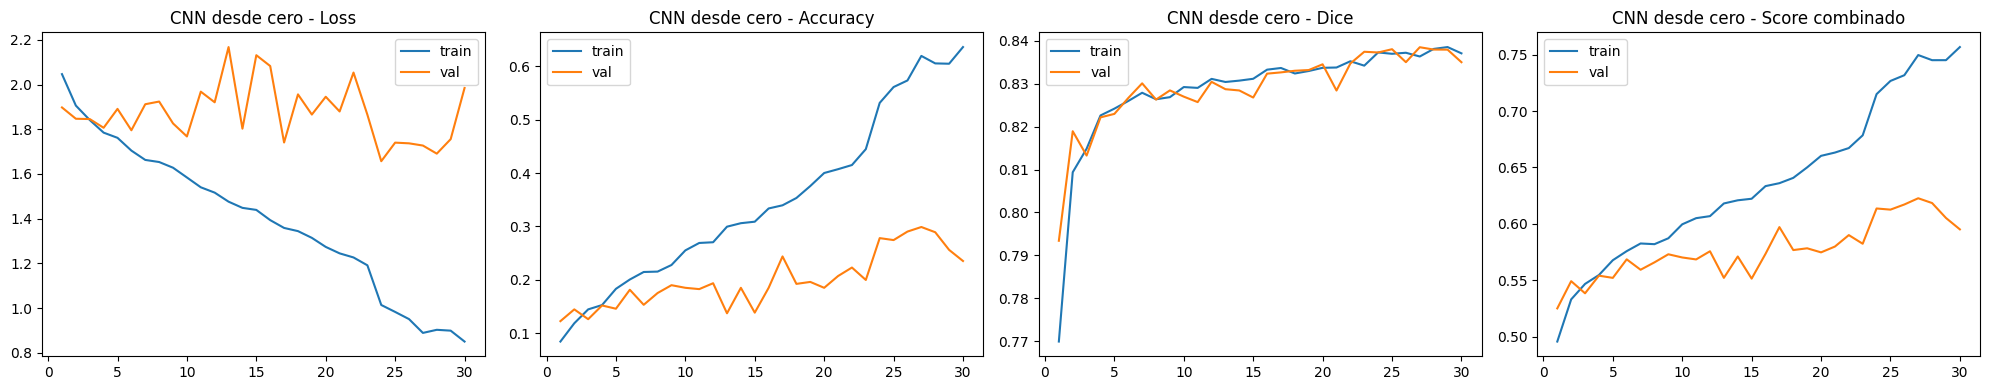


CNN + Optuna: mejor checkpoint cargado en época 27 con score=0.6227


In [47]:
print("\nEntrenando CNN desde cero con parametros optimos...")

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

train_dl_cnn = DataLoader(train_ds, batch_size=cnn_best_batch_size, shuffle=True, num_workers=2)
val_dl_cnn = DataLoader(val_ds, batch_size=cnn_best_batch_size, shuffle=False, num_workers=2)

model_cnn = ModelCNN().to(device)
initialize_weights(model_cnn)

model_cnn.cls_head = build_cls_head(model_cnn.feat_dim, 22, cnn_best_hidden_dim, cnn_best_n_layers, cnn_best_dropout).to(device)
model_cnn.reg_head = build_reg_head(model_cnn.feat_dim, cnn_best_hidden_dim, cnn_best_n_layers, cnn_best_dropout).to(device)

initialize_weights(model_cnn.cls_head)
initialize_weights(model_cnn.reg_head)

params = filter(lambda p: p.requires_grad, model_cnn.parameters())

if cnn_best_optimizer == 'Adam':
    opt_cnn = torch.optim.Adam(params, lr=cnn_best_lr, weight_decay=cnn_best_weight_decay)
else:
    opt_cnn = torch.optim.AdamW(params, lr=cnn_best_lr, weight_decay=cnn_best_weight_decay)

# Ahora el scheduler maximiza score combinado
sched_cnn = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt_cnn, mode='max', factor=cnn_best_factor_sched, patience=5
)

# Early stopping basado en score combinado


es_cnn = EarlyStoppingScore(patience=8, min_delta=0.0001)
best_score_cnn = -float('inf')
history_cnn = []
START_EPOCH_CNN = 0

if os.path.exists('best_model_cnn.pth'):
    ckpt = torch.load('best_model_cnn.pth')
    model_cnn.load_state_dict(ckpt['model_state_dict'])
    try:
        opt_cnn.load_state_dict(ckpt['optimizer_state_dict'])
    except:
        pass
    history_cnn = ckpt.get('history', [])
    best_score_cnn = ckpt.get('score_combinado', -float('inf'))
    START_EPOCH_CNN = ckpt.get('epoch', 0)
    print(f"Retomando CNN desde época {START_EPOCH_CNN} "
          f"(score={best_score_cnn:.4f})")
else:
    print("Entrenando CNN desde cero")

for epoch in range(START_EPOCH_CNN, 30):
    print(f"\n{'='*50}")
    print(f"Época {epoch+1}/30")
    print(f"{'='*50}")

    tr = run_epoch(model_cnn, train_dl_cnn, opt_cnn, alpha=cnn_best_alpha, device=device, train=True)
    vl = run_epoch(model_cnn, val_dl_cnn, opt_cnn, alpha=cnn_best_alpha, device=device, train=False)

    train_score = 0.6 * tr['dice'] + 0.4 * tr['accuracy']
    val_score = 0.6 * vl['dice'] + 0.4 * vl['accuracy']

    # scheduler ahora usa score
    sched_cnn.step(val_score)
    print(f"  LR actual: {opt_cnn.param_groups[0]['lr']:.6f}")

    history_cnn.append({
        'epoch': epoch + 1,
        'train_acc': tr['accuracy'],
        'val_acc': vl['accuracy'],
        'train_dice': tr['dice'],
        'val_dice': vl['dice'],
        'train_loss': tr['loss'],
        'val_loss': vl['loss'],
        'train_score': train_score,
        'val_score': val_score,
    })

    print(f"\n  {'':10} {'loss':>8} {'accuracy':>10} {'dice':>10} {'score':>10}")
    print(f"  {'train':10} {tr['loss']:>8.4f} "
          f"{tr['accuracy']:>10.4f} {tr['dice']:>10.4f} {train_score:>10.4f}")
    print(f"  {'val':10} {vl['loss']:>8.4f} "
          f"{vl['accuracy']:>10.4f} {vl['dice']:>10.4f} {val_score:>10.4f}")

    if val_score > best_score_cnn:
        best_score_cnn = val_score

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_cnn.state_dict(),
            'optimizer_state_dict': opt_cnn.state_dict(),
            'val_loss': vl['loss'],
            'score_combinado': best_score_cnn,
            'history': history_cnn,
        }, 'best_model_cnn.pth')
        print(f"  ✓ Mejor modelo guardado (score={best_score_cnn:.4f})")

    print(f"  Score combinado (0.6*dice + 0.4*acc): {val_score:.4f}")

    if es_cnn.step(val_score, model_cnn):
        print(f"Early stopping en epoca {epoch+1}")
        break

ckpt_cnn = torch.load('best_model_cnn.pth')
model_cnn.load_state_dict(ckpt_cnn['model_state_dict'])
print(f"\n📦 CNN cargada — época {ckpt_cnn.get('epoch', '?')} "
      f"(score={ckpt_cnn.get('score_combinado', float('nan')):.4f})")

# ── Graficas CNN ─────────────────────────────────────────────
df_cnn = pd.DataFrame(history_cnn)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].plot(df_cnn['epoch'], df_cnn['train_loss'], label='train')
axes[0].plot(df_cnn['epoch'], df_cnn['val_loss'], label='val')
axes[0].set_title('CNN desde cero - Loss')
axes[0].legend()

axes[1].plot(df_cnn['epoch'], df_cnn['train_acc'], label='train')
axes[1].plot(df_cnn['epoch'], df_cnn['val_acc'], label='val')
axes[1].set_title('CNN desde cero - Accuracy')
axes[1].legend()

axes[2].plot(df_cnn['epoch'], df_cnn['train_dice'], label='train')
axes[2].plot(df_cnn['epoch'], df_cnn['val_dice'], label='val')
axes[2].set_title('CNN desde cero - Dice')
axes[2].legend()

axes[3].plot(df_cnn['epoch'], df_cnn['train_score'], label='train')
axes[3].plot(df_cnn['epoch'], df_cnn['val_score'], label='val')
axes[3].set_title('CNN desde cero - Score combinado')
axes[3].legend()

plt.tight_layout()
plt.show()

cnn_final_acc = df_cnn['val_acc'].iloc[-1]
cnn_final_dice = df_cnn['val_dice'].iloc[-1]
cnn_final_score = df_cnn['val_score'].iloc[-1]

print(f"\nCNN + Optuna: mejor checkpoint cargado en época "
      f"{ckpt_cnn.get('epoch', '?')} con "
      f"score={ckpt_cnn.get('score_combinado', float('nan')):.4f}")

### Resultados
 
El CNN desde cero logró val_accuracy=30% y val_dice=0.838 (score=0.6227).

Aunque la localización fue razonable, la clasificación de 22 clases sin pesos preentrenados resultó difícil con solo 1375 imágenes de entrenamiento.

Esto confirma el rol del CNN como baseline y justifica el uso de transfer learning.

## 12.2 Entrenamiento 2 - EfficientNet-B2

Se ajusta EfficientNet-B2 mediante fine-tuning para adaptar sus representaciones preentrenadas al dominio del dataset. Este enfoque permite aprovechar conocimiento previo y, al mismo tiempo, especializar el modelo para la tarea actual.

Optuna encontró: lr=0.00323, dropout=0.49, weight_decay=0.0152, batch_size=16, optimizer=AdamW, hidden_dim=256, alpha=0.636.

Resultados (mejor checkpoint época 23, score=0.8872):

- Val accuracy: 83.7% — mejora de 54 puntos vs CNN desde cero.
- Val Dice: 0.921 — excelente localización.
- Early stopping en época 33.

In [48]:
def objective_eff(trial):
    lr = trial.suggest_float('lr', 1e-5, 5e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-4, 5e-2, log=True)
    dropout = trial.suggest_float('dropout', 0.3, 0.6)
    alpha = trial.suggest_float('alpha', 0.2, 0.7)
    factor_sched = trial.suggest_float('factor_sched', 0.2, 0.8)
    batch_size = trial.suggest_categorical('batch_size', [8, 16, 32])
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'AdamW'])
    hidden_dim = trial.suggest_categorical('hidden_dim', [256, 512])
    n_layers = trial.suggest_int('n_layers', 1, 3)
    n_epochs_trial = trial.suggest_int('n_epochs_trial', 5, 8)

    gc.collect()
    torch.cuda.empty_cache()

    tr_dl = DataLoader(train_ds_imagenet, batch_size=batch_size, shuffle=True, num_workers=2)
    vl_dl = DataLoader(val_ds_imagenet,   batch_size=batch_size, shuffle=False, num_workers=2) 
    model_eff = ModelEfficientNet(input_shape=(3, 416, 416)).to(device)
    model_eff.cls_head = build_cls_head(
        model_eff.feat_dim, 22, hidden_dim, n_layers, dropout
    ).to(device)
    model_eff.reg_head = build_reg_head(
        model_eff.feat_dim, hidden_dim, n_layers, dropout
    ).to(device)

    params = filter(lambda p: p.requires_grad, model_eff.parameters())
    opt = (torch.optim.Adam if optimizer_name == 'Adam' else torch.optim.AdamW)(
        params, lr=lr, weight_decay=weight_decay
    )

    sched_t = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='max', factor=factor_sched, patience=2
    )

    best_score = 0.0
    for _ in range(n_epochs_trial):
        run_epoch(model_eff, tr_dl, opt, alpha=alpha, device=device, train=True)
        vm = run_epoch(model_eff, vl_dl, opt, alpha=alpha, device=device, train=False)

        score = 0.6 * vm['dice'] + 0.4 * vm['accuracy']
        sched_t.step(score)

        if score > best_score:
            best_score = score

    del model_eff
    gc.collect()
    torch.cuda.empty_cache()

    return 1.0 - best_score

In [49]:
print("Buscando mejores hiperparametros para EfficientNet-B2 (12 trials)...")

study_eff = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_eff.optimize(objective_eff, n_trials=12, show_progress_bar=True)

eff_best_lr = study_eff.best_params['lr']
eff_best_weight_decay = study_eff.best_params['weight_decay']
eff_best_dropout = study_eff.best_params['dropout']
eff_best_alpha = study_eff.best_params['alpha']
eff_best_factor_sched = study_eff.best_params['factor_sched']
eff_best_batch_size = study_eff.best_params['batch_size']
eff_best_optimizer = study_eff.best_params['optimizer']
eff_best_hidden_dim = study_eff.best_params['hidden_dim']
eff_best_n_layers = study_eff.best_params['n_layers']

print("\n=== MEJORES HIPERPARAMETROS EFFICIENTNET-B2 ===")
for k, v in study_eff.best_params.items():
    print(f"  {k:<22} = {v}")
print(f"  {'score':<22} = {1 - study_eff.best_value:.4f}")

Buscando mejores hiperparametros para EfficientNet-B2 (12 trials)...


  0%|          | 0/12 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth



  0%|          | 0.00/35.2M [00:00<?, ?B/s]
 26%|██▌       | 9.00M/35.2M [00:00<00:00, 94.2MB/s]
100%|██████████| 35.2M/35.2M [00:00<00:00, 152MB/s] 



=== MEJORES HIPERPARAMETROS EFFICIENTNET-B2 ===
  lr                     = 0.003230175187384699
  weight_decay           = 0.01517374091270361
  dropout                = 0.49002112695312705
  alpha                  = 0.6357302950938588
  factor_sched           = 0.6822032461394687
  batch_size             = 16
  optimizer              = AdamW
  hidden_dim             = 256
  n_layers               = 1
  n_epochs_trial         = 6
  score                  = 0.8223


### Análisis de EfficientNet

EfficientNet-B2 combina eficiencia computacional con alta capacidad de representación. Su preentrenamiento permite capturar patrones visuales relevantes desde el inicio del entrenamiento, lo que mejora el desempeño tanto en clasificación como en localización.



EfficientNet-B2 logró val_accuracy=83.7% y val_dice=0.921 (score=0.8872).

El salto respecto al CNN desde cero (+54 pts en accuracy) confirma el valor del preentrenamiento. Sin embargo, el lr=0.00323 encontrado por Optuna resultó alto para fine-tuning — el modelo llegó a train_acc≈99% en época 33, indicando overfitting en clasificación. El early stopping controló esto cargando el mejor checkpoint de época 23.


Entrenando EfficientNet-B2 con parametros optimos...
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Cabezas EfficientNet inicializadas con Xavier
Entrenando EfficientNet desde cero

[EfficientNet] Época 1/80
  LR actual: 0.003230

                 loss   accuracy       dice      score
  train        1.0261     0.3412     0.7107     0.5629
  val          0.7892     0.4926     0.7698     0.6589
  ✓ Mejor modelo guardado (score=0.6589)
  Score combinado (0.6*dice + 0.4*acc): 0.6589
  ✓ Mejor modelo guardado (score=0.6589)

[EfficientNet] Época 2/80
  LR actual: 0.003230

                 loss   accuracy       dice      score
  train        0.6144     0.6089     0.7978     0.7222
  val          0.6085     0.6019     0.8195     0.7325
  ✓ Mejor modelo guardado (score=0.7325)
  Score combinado (0.6*dice + 0.4*acc): 0.7325
  ✓ Mejor modelo guardado (score=0.7325)

[EfficientNet] Época 3/80
  LR actual: 0.003230

                 loss   accuracy       dice  

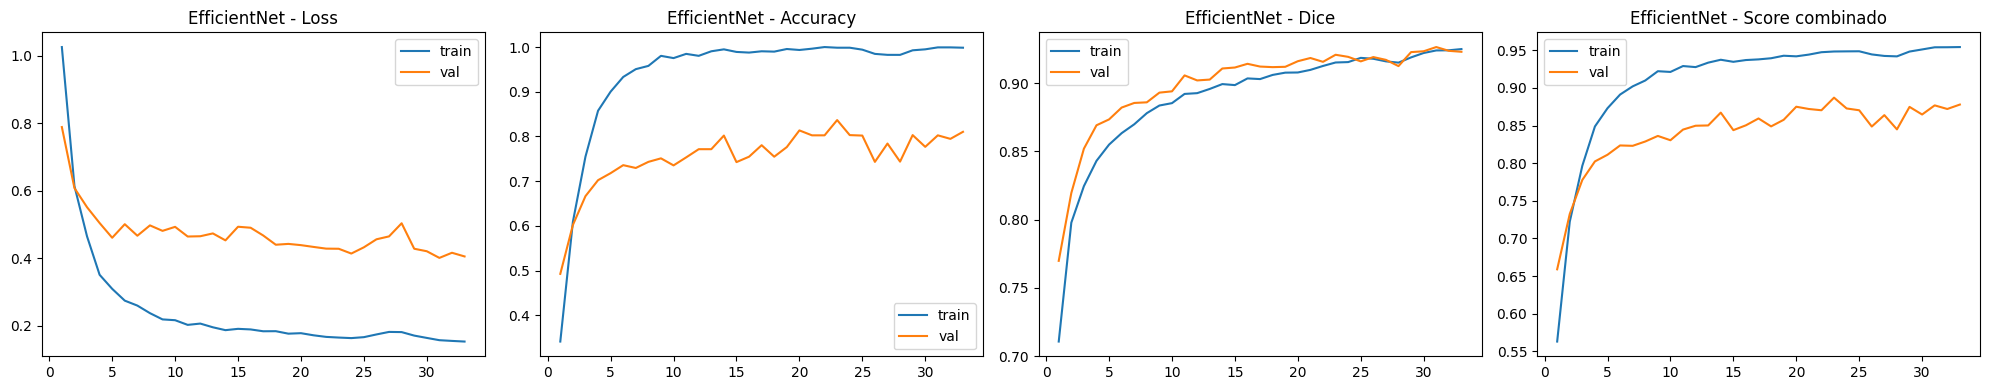


EfficientNet-B2 + Optuna: mejor checkpoint cargado en época 23 con score=0.8872


In [80]:
print("\nEntrenando EfficientNet-B2 con parametros optimos...")

gc.collect()
torch.cuda.empty_cache()

train_dl_eff = DataLoader(train_ds_imagenet, batch_size=eff_best_batch_size, shuffle=True, num_workers=2)
val_dl_eff   = DataLoader(val_ds_imagenet,   batch_size=eff_best_batch_size, shuffle=False, num_workers=2)

model_eff = ModelEfficientNet(input_shape=(3, 416, 416)).to(device)
model_eff.cls_head = build_cls_head(model_eff.feat_dim, 22, eff_best_hidden_dim, eff_best_n_layers, eff_best_dropout).to(device)
model_eff.reg_head = build_reg_head(model_eff.feat_dim, eff_best_hidden_dim, eff_best_n_layers, eff_best_dropout).to(device)

initialize_weights(model_eff.cls_head)
initialize_weights(model_eff.reg_head)
print("✓ Cabezas EfficientNet inicializadas con Xavier")

params = filter(lambda p: p.requires_grad, model_eff.parameters())

if eff_best_optimizer == 'Adam':
    opt_eff = torch.optim.Adam(params, lr=eff_best_lr, weight_decay=eff_best_weight_decay)
else:
    opt_eff = torch.optim.AdamW(params, lr=eff_best_lr, weight_decay=eff_best_weight_decay)

# 🔥 Scheduler ahora maximiza score
sched_eff = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt_eff, mode='max', factor=eff_best_factor_sched, patience=5
)

es_eff = EarlyStoppingScore(patience=10, min_delta=0.0001)

best_score_eff = -float('inf')
history_eff = []
START_EPOCH_EFF = 0

if os.path.exists('best_model_eff.pth'):
    ckpt = torch.load('best_model_eff.pth')
    model_eff.load_state_dict(ckpt['model_state_dict'])
    try:
        opt_eff.load_state_dict(ckpt['optimizer_state_dict'])
    except:
        pass
    history_eff = ckpt.get('history', [])
    best_score_eff = ckpt.get('score_combinado', -float('inf'))
    START_EPOCH_EFF = ckpt.get('epoch', 0)
    print(f"Retomando EfficientNet desde época {START_EPOCH_EFF} "
          f"(score={best_score_eff:.4f})")
else:
    print("Entrenando EfficientNet desde cero")

for epoch in range(START_EPOCH_EFF, 80):

    print(f"\n{'='*50}")
    print(f"[EfficientNet] Época {epoch+1}/80")
    print(f"{'='*50}")

    tr = run_epoch(model_eff, train_dl_eff, opt_eff, alpha=eff_best_alpha, device=device, train=True)
    vl = run_epoch(model_eff, val_dl_eff, opt_eff, alpha=eff_best_alpha, device=device, train=False)

    train_score = 0.6 * tr['dice'] + 0.4 * tr['accuracy']
    val_score = 0.6 * vl['dice'] + 0.4 * vl['accuracy']

    # 🔥 scheduler usa score
    sched_eff.step(val_score)
    print(f"  LR actual: {opt_eff.param_groups[0]['lr']:.6f}")

    history_eff.append({
        'epoch': epoch + 1,
        'train_acc': tr['accuracy'],
        'val_acc': vl['accuracy'],
        'train_dice': tr['dice'],
        'val_dice': vl['dice'],
        'train_loss': tr['loss'],
        'val_loss': vl['loss'],
        'train_score': train_score,
        'val_score': val_score,
    })

    print(f"\n  {'':10} {'loss':>8} {'accuracy':>10} {'dice':>10} {'score':>10}")
    print(f"  {'train':10} {tr['loss']:>8.4f} "
          f"{tr['accuracy']:>10.4f} {tr['dice']:>10.4f} {train_score:>10.4f}")
    print(f"  {'val':10} {vl['loss']:>8.4f} "
          f"{vl['accuracy']:>10.4f} {vl['dice']:>10.4f} {val_score:>10.4f}")

    # 🔥 Guardado por score
    if val_score > best_score_eff:
        best_score_eff = val_score

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_eff.state_dict(),
            'optimizer_state_dict': opt_eff.state_dict(),
            'val_loss': vl['loss'],
            'score_combinado': best_score_eff,
            'history': history_eff,
        }, 'best_model_eff.pth')

        print(f"  ✓ Mejor modelo guardado (score={best_score_eff:.4f})")

    print(f"  Score combinado (0.6*dice + 0.4*acc): {val_score:.4f}")

    # 🔥 Early stopping por score
    if es_eff.step(val_score, model_eff):
        print(f"Early stopping en epoca {epoch+1}")
        break

ckpt_eff = torch.load('best_model_eff.pth')
model_eff.load_state_dict(ckpt_eff['model_state_dict'])

print(f"\n📦 EfficientNet cargado — época {ckpt_eff.get('epoch', '?')} "
      f"(score={ckpt_eff.get('score_combinado', float('nan')):.4f})")

# ── Gráficas ─────────────────────────────────────────────
df_eff = pd.DataFrame(history_eff)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].plot(df_eff['epoch'], df_eff['train_loss'], label='train')
axes[0].plot(df_eff['epoch'], df_eff['val_loss'], label='val')
axes[0].set_title('EfficientNet - Loss')
axes[0].legend()

axes[1].plot(df_eff['epoch'], df_eff['train_acc'], label='train')
axes[1].plot(df_eff['epoch'], df_eff['val_acc'], label='val')
axes[1].set_title('EfficientNet - Accuracy')
axes[1].legend()

axes[2].plot(df_eff['epoch'], df_eff['train_dice'], label='train')
axes[2].plot(df_eff['epoch'], df_eff['val_dice'], label='val')
axes[2].set_title('EfficientNet - Dice')
axes[2].legend()

axes[3].plot(df_eff['epoch'], df_eff['train_score'], label='train')
axes[3].plot(df_eff['epoch'], df_eff['val_score'], label='val')
axes[3].set_title('EfficientNet - Score combinado')
axes[3].legend()

plt.tight_layout()
plt.show()

print(f"\nEfficientNet-B2 + Optuna: mejor checkpoint cargado en época "
      f"{ckpt_eff.get('epoch', '?')} con "
      f"score={ckpt_eff.get('score_combinado', float('nan')):.4f}")

## 12.3. Entrenamiento 3 - ConvNeXt-Tiny

Se entrena ConvNeXt-Tiny como segunda alternativa de transfer learning. Su comparación con EfficientNet permite analizar si una arquitectura más moderna logra un mejor equilibrio multitarea en este dataset.



Optuna encontró: lr=0.000397, dropout=0.482, weight_decay=0.000133, batch_size=16, optimizer=Adam, hidden_dim=256, alpha=0.385.

Resultados (mejor checkpoint época 49, score=0.9074):

- Val accuracy: 87.0% — mejor de los tres modelos.
- Val Dice: 0.932 — mejor de los tres modelos.
- Early stopping en época 59.
- Convergencia más estable que EfficientNet gracias al lr más bajo.

In [51]:
def objective_convnext(trial):
    lr = trial.suggest_float('lr', 1e-5, 5e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-4, 5e-2, log=True)
    dropout = trial.suggest_float('dropout', 0.3, 0.6)
    alpha = trial.suggest_float('alpha', 0.3, 0.8)
    factor_sched = trial.suggest_float('factor_sched', 0.2, 0.8)
    batch_size = trial.suggest_categorical('batch_size', [8, 16, 32])
    optimizer_name = trial.suggest_categorical('optimizer', ['Adam', 'AdamW'])
    hidden_dim = trial.suggest_categorical('hidden_dim', [256, 512])
    n_layers = trial.suggest_int('n_layers', 1, 3)
    n_epochs_trial = trial.suggest_int('n_epochs_trial', 5, 8)

    gc.collect()
    torch.cuda.empty_cache()

    tr_dl = DataLoader(train_ds_imagenet, batch_size=batch_size, shuffle=True, num_workers=2)
    vl_dl = DataLoader(val_ds_imagenet,   batch_size=batch_size, shuffle=False, num_workers=2)

    model_cx = ModelConvNeXt().to(device)
    model_cx.cls_head = build_cls_head(model_cx.feat_dim, 22, hidden_dim, n_layers, dropout).to(device)
    model_cx.reg_head = build_reg_head(model_cx.feat_dim, hidden_dim, n_layers, dropout).to(device)

    params = filter(lambda p: p.requires_grad, model_cx.parameters())
    opt = (torch.optim.Adam if optimizer_name == 'Adam' else torch.optim.AdamW)(
        params, lr=lr, weight_decay=weight_decay
    )

    sched_t = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='max', factor=factor_sched, patience=2
    )

    best_score = 0.0
    for _ in range(n_epochs_trial):
        run_epoch(model_cx, tr_dl, opt, alpha=alpha, device=device, train=True)
        vm = run_epoch(model_cx, vl_dl, opt, alpha=alpha, device=device, train=False)

        score = 0.6 * vm['dice'] + 0.4 * vm['accuracy']
        sched_t.step(score)

        if score > best_score:
            best_score = score

    del model_cx
    gc.collect()
    torch.cuda.empty_cache()

    return 1.0 - best_score

In [52]:
print("Buscando mejores hiperparametros para ConvNeXt-Tiny (8 trials)...")

study_convnext = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_convnext.optimize(objective_convnext, n_trials=8, show_progress_bar=True)

cx_best_lr = study_convnext.best_params['lr']
cx_best_weight_decay = study_convnext.best_params['weight_decay']
cx_best_dropout = study_convnext.best_params['dropout']
cx_best_alpha = study_convnext.best_params['alpha']
cx_best_factor_sched = study_convnext.best_params['factor_sched']
cx_best_batch_size = study_convnext.best_params['batch_size']
cx_best_optimizer = study_convnext.best_params['optimizer']
cx_best_hidden_dim = study_convnext.best_params['hidden_dim']
cx_best_n_layers = study_convnext.best_params['n_layers']

print("\n=== MEJORES HIPERPARAMETROS CONVNEXT-TINY ===")
for k, v in study_convnext.best_params.items():
    print(f"  {k:<22} = {v}")
print(f"  {'score':<22} = {1 - study_convnext.best_value:.4f}")


Buscando mejores hiperparametros para ConvNeXt-Tiny (8 trials)...


  0%|          | 0/8 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth



  0%|          | 0.00/109M [00:00<?, ?B/s]
  8%|▊         | 9.00M/109M [00:00<00:01, 94.3MB/s]
 26%|██▋       | 28.8M/109M [00:00<00:00, 161MB/s] 
 44%|████▍     | 48.4M/109M [00:00<00:00, 181MB/s]
 62%|██████▏   | 67.2M/109M [00:00<00:00, 187MB/s]
100%|██████████| 109M/109M [00:00<00:00, 194MB/s] 



=== MEJORES HIPERPARAMETROS CONVNEXT-TINY ===
  lr                     = 0.00039710847107924746
  weight_decay           = 0.00013346527038305943
  dropout                = 0.4822634555704315
  alpha                  = 0.38526206184364575
  factor_sched           = 0.23903095579116773
  batch_size             = 16
  optimizer              = Adam
  hidden_dim             = 256
  n_layers               = 1
  n_epochs_trial         = 6
  score                  = 0.8544



Entrenando ConvNeXt-Tiny con parametros optimos...
✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
✓ Cabezas ConvNeXt inicializadas con Xavier
Entrenando ConvNeXt desde cero

[ConvNeXt] Época 1/80
  LR actual: 0.000397

                 loss   accuracy       dice      score
  train        1.7352     0.2372     0.6771     0.5011
  val          1.0282     0.4548     0.7814     0.6508
  ✓ Mejor modelo guardado (score=0.6508)
  Score combinado (0.6*dice + 0.4*acc): 0.6508
  ✓ Mejor modelo guardado (score=0.6508)

[ConvNeXt] Época 2/80
  LR actual: 0.000397

                 loss   accuracy       dice      score
  train        0.9068     0.5905     0.7765     0.7021
  val          0.7694     0.6366     0.7938     0.7309
  ✓ Mejor modelo guardado (score=0.7309)
  Score combinado (0.6*dice + 0.4*acc): 0.7309
  ✓ Mejor modelo guardado (score=0.7309)

[ConvNeXt] Época 3/80
  LR actual: 0.000397

                 loss   accuracy       dice      score
  train     

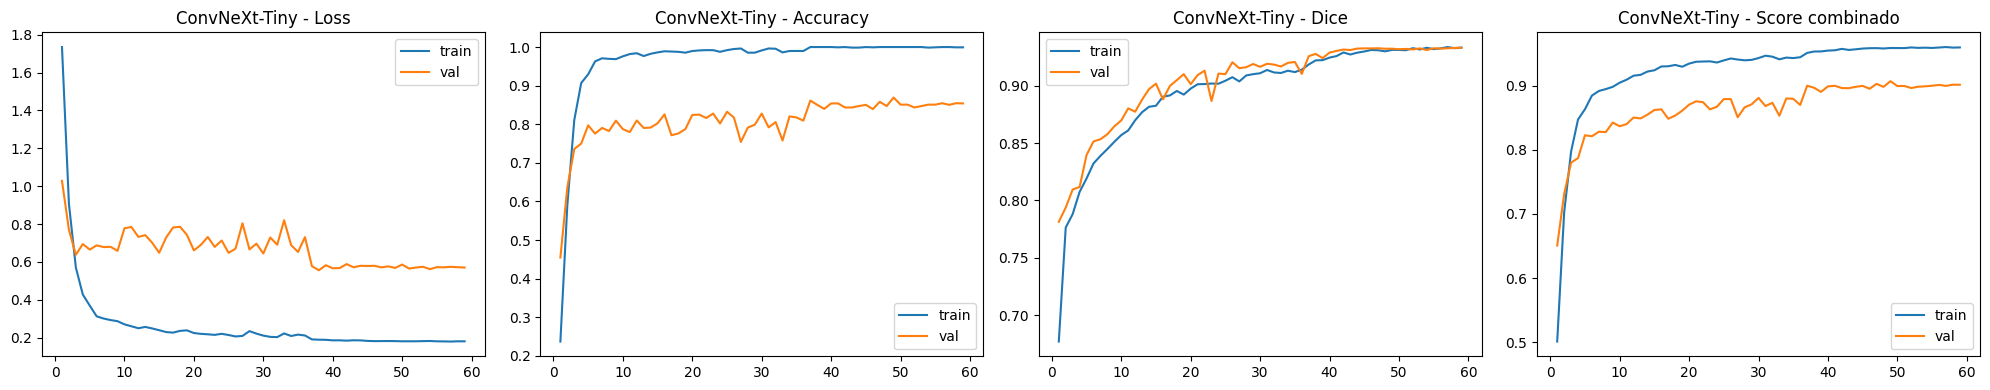


ConvNeXt-Tiny + Optuna: mejor checkpoint cargado en época 49 con score=0.9070


In [53]:
print("\nEntrenando ConvNeXt-Tiny con parametros optimos...")

gc.collect()
torch.cuda.empty_cache()

train_dl_cx = DataLoader(train_ds_imagenet, batch_size=cx_best_batch_size, shuffle=True, num_workers=2)
val_dl_cx   = DataLoader(val_ds_imagenet,   batch_size=cx_best_batch_size, shuffle=False, num_workers=2)

model_cx = ModelConvNeXt().to(device)
model_cx.cls_head = build_cls_head(model_cx.feat_dim, 22, cx_best_hidden_dim, cx_best_n_layers, cx_best_dropout).to(device)
model_cx.reg_head = build_reg_head(model_cx.feat_dim, cx_best_hidden_dim, cx_best_n_layers, cx_best_dropout).to(device)

initialize_weights(model_cx.cls_head)
initialize_weights(model_cx.reg_head)
print("✓ Cabezas ConvNeXt inicializadas con Xavier")

params = filter(lambda p: p.requires_grad, model_cx.parameters())

if cx_best_optimizer == 'Adam':
    opt_cx = torch.optim.Adam(params, lr=cx_best_lr, weight_decay=cx_best_weight_decay)
else:
    opt_cx = torch.optim.AdamW(params, lr=cx_best_lr, weight_decay=cx_best_weight_decay)

# Scheduler ahora maximiza score
sched_cx = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt_cx, mode='max', factor=cx_best_factor_sched, patience=5
)

es_cx = EarlyStoppingScore(patience=10, min_delta=0.0001)

best_score_cx = -float('inf')
history_cx = []
START_EPOCH_CX = 0

if os.path.exists('best_model_convnext.pth'):
    ckpt = torch.load('best_model_convnext.pth')
    model_cx.load_state_dict(ckpt['model_state_dict'])
    try:
        opt_cx.load_state_dict(ckpt['optimizer_state_dict'])
    except:
        pass
    history_cx = ckpt.get('history', [])
    best_score_cx = ckpt.get('score_combinado', -float('inf'))
    START_EPOCH_CX = ckpt.get('epoch', 0)
    print(f"Retomando ConvNeXt desde época {START_EPOCH_CX} "
          f"(score={best_score_cx:.4f})")
else:
    print("Entrenando ConvNeXt desde cero")

for epoch in range(START_EPOCH_CX, 80):

    print(f"\n{'='*50}")
    print(f"[ConvNeXt] Época {epoch+1}/80")
    print(f"{'='*50}")

    tr = run_epoch(model_cx, train_dl_cx, opt_cx, alpha=cx_best_alpha, device=device, train=True)
    vl = run_epoch(model_cx, val_dl_cx, opt_cx, alpha=cx_best_alpha, device=device, train=False)

    train_score = 0.6 * tr['dice'] + 0.4 * tr['accuracy']
    val_score = 0.6 * vl['dice'] + 0.4 * vl['accuracy']

    # Scheduler por score
    sched_cx.step(val_score)
    print(f"  LR actual: {opt_cx.param_groups[0]['lr']:.6f}")

    history_cx.append({
        'epoch': epoch + 1,
        'train_acc': tr['accuracy'],
        'val_acc': vl['accuracy'],
        'train_dice': tr['dice'],
        'val_dice': vl['dice'],
        'train_loss': tr['loss'],
        'val_loss': vl['loss'],
        'train_score': train_score,
        'val_score': val_score,
    })

    print(f"\n  {'':10} {'loss':>8} {'accuracy':>10} {'dice':>10} {'score':>10}")
    print(f"  {'train':10} {tr['loss']:>8.4f} "
          f"{tr['accuracy']:>10.4f} {tr['dice']:>10.4f} {train_score:>10.4f}")
    print(f"  {'val':10} {vl['loss']:>8.4f} "
          f"{vl['accuracy']:>10.4f} {vl['dice']:>10.4f} {val_score:>10.4f}")

    if val_score > best_score_cx:
        best_score_cx = val_score

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_cx.state_dict(),
            'optimizer_state_dict': opt_cx.state_dict(),
            'val_loss': vl['loss'],
            'score_combinado': best_score_cx,
            'history': history_cx,
        }, 'best_model_convnext.pth')

        print(f"  ✓ Mejor modelo guardado (score={best_score_cx:.4f})")

    print(f"  Score combinado (0.6*dice + 0.4*acc): {val_score:.4f}")

    if es_cx.step(val_score, model_cx):
        print(f"Early stopping en epoca {epoch+1}")
        break

ckpt_cx = torch.load('best_model_convnext.pth')
model_cx.load_state_dict(ckpt_cx['model_state_dict'])
print(f"\n📦 ConvNeXt cargado — época {ckpt_cx.get('epoch', '?')} "
      f"(score={ckpt_cx.get('score_combinado', float('nan')):.4f})")

df_cx = pd.DataFrame(history_cx)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].plot(df_cx['epoch'], df_cx['train_loss'], label='train')
axes[0].plot(df_cx['epoch'], df_cx['val_loss'], label='val')
axes[0].set_title('ConvNeXt-Tiny - Loss')
axes[0].legend()

axes[1].plot(df_cx['epoch'], df_cx['train_acc'], label='train')
axes[1].plot(df_cx['epoch'], df_cx['val_acc'], label='val')
axes[1].set_title('ConvNeXt-Tiny - Accuracy')
axes[1].legend()

axes[2].plot(df_cx['epoch'], df_cx['train_dice'], label='train')
axes[2].plot(df_cx['epoch'], df_cx['val_dice'], label='val')
axes[2].set_title('ConvNeXt-Tiny - Dice')
axes[2].legend()

axes[3].plot(df_cx['epoch'], df_cx['train_score'], label='train')
axes[3].plot(df_cx['epoch'], df_cx['val_score'], label='val')
axes[3].set_title('ConvNeXt-Tiny - Score combinado')
axes[3].legend()

plt.tight_layout()
plt.show()

cx_final_acc = df_cx['val_acc'].iloc[-1]
cx_final_dice = df_cx['val_dice'].iloc[-1]

print(f"\nConvNeXt-Tiny + Optuna: mejor checkpoint cargado en época "
      f"{ckpt_cx.get('epoch', '?')} con "
      f"score={ckpt_cx.get('score_combinado', float('nan')):.4f}")

### Análisis de ConvNeXt

ConvNeXt-Tiny es una arquitectura moderna que incorpora ideas recientes en visión por computador, manteniendo una base convolucional.

Su desempeño competitivo indica que es capaz de aprender representaciones ricas, aunque su ventaja frente a EfficientNet puede depender del tamaño del dataset y la configuración del entrenamiento.


ConvNeXt-Tiny obtuvo el mejor score combinado (0.9074), superando a EfficientNet (0.8873) en accuracy (+3.3 pts) y Dice (+1.1 pts). 

Su lr más bajo (0.000397 vs 0.00323 de EfficientNet) produjo convergencia más gradual pero evitó el overfitting severo. 
Llegó al early stopping en época 59, 26 épocas más que EfficientNet, aprovechando mejor su capacidad.

## 13. Comparación final y selección del mejor modelo

Una vez entrenados los tres modelos, se comparan sus métricas de validación para identificar cuál ofrece el mejor equilibrio entre clasificación y localización.

La selección final no se basa únicamente en la pérdida total, sino en un criterio más interpretable desde el punto de vista del problema.

### Criterio de selección del modelo

La selección del mejor modelo se realizó utilizando un score combinado definido como:


Score = 0.6 Dice + 0.4 Accuracy


Se asigna mayor peso al Dice debido a la importancia de la localización precisa del objeto, mientras que la Accuracy evalúa la correcta clasificación del vehículo.

Este criterio permite seleccionar el modelo con mejor balance entre ambas tareas, evitando depender únicamente de la pérdida total.

| Modelo       | Val Acc | Val Dice | Score  |
|--------------|---------|----------|--------|
| ConvNeXt     | 87.0%   | 0.9321   | 0.9074 |
| EfficientNet | 83.7%   | 0.9208   | 0.8873 |
| CNN propio   | 30.0%   | 0.8382   | 0.6229 |

ConvNeXt supera en ambas tareas. El CNN confirma que sin preentrenamiento la clasificación de 22 clases con ~1375 imágenes es muy difícil.

Cargando mejores pesos...
  CNN          — época 27 | val_loss=1.7271
  EfficientNet — época 23 | val_loss=0.4287
  ConvNeXt     — época 49 | val_loss=0.5678

           Métrica | CNN propio | EfficientNet |   ConvNeXt |    Ganador
          Val Loss |     1.7243 |       0.4273 |     0.5636 | EfficientNet
      Val Cls Loss |     2.6784 |       0.9941 |     0.8612 |   ConvNeXt
      Val Reg Loss |     0.1932 |       0.1025 |     0.0886 |   ConvNeXt
      Val Accuracy |     0.3000 |       0.8370 |     0.8704 |   ConvNeXt
          Val Dice |     0.8382 |       0.9208 |     0.9321 |   ConvNeXt


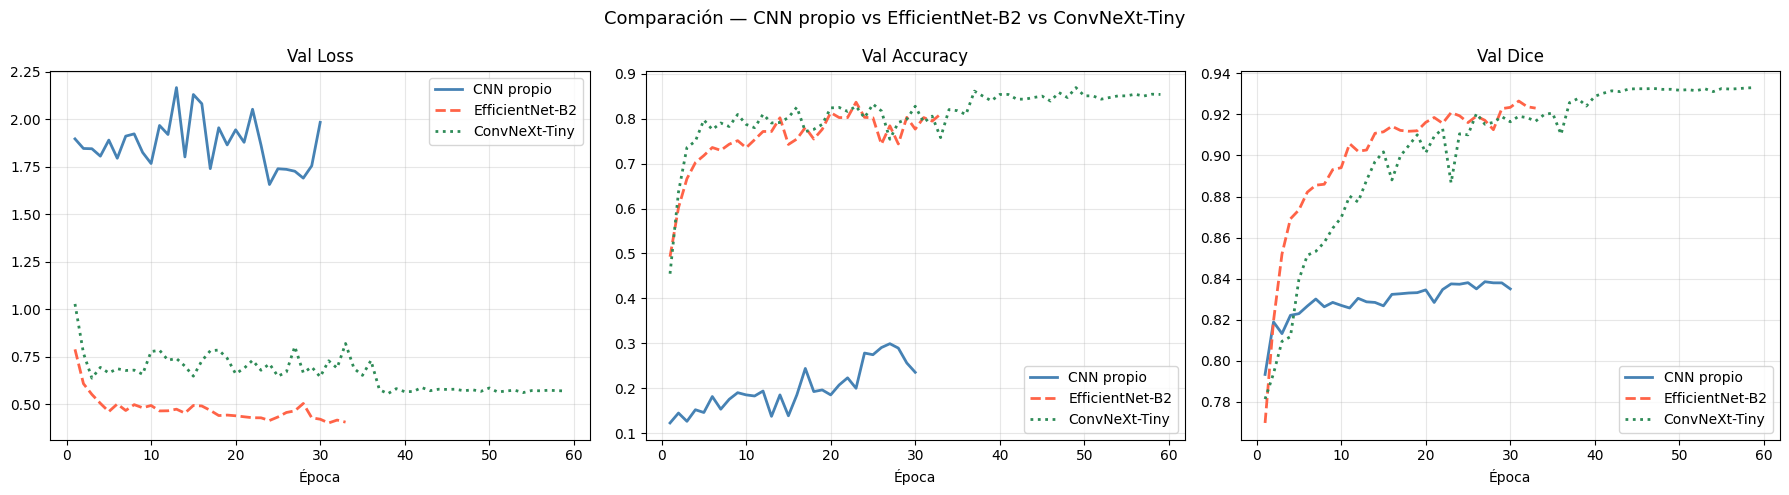

In [81]:
def compute_final_metrics(model, loader, device, alpha):
    model.eval()

    total_loss = 0.0
    total_cls_loss = 0.0
    total_reg_loss = 0.0
    total_acc = 0.0
    total_dice = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in loader:
            imgs = batch['image'].float().to(device)

            labels = {
                'class_id': batch['class_id'].to(device),
                'bbox': batch['bbox'].float().to(device)
            }

            batch_size = imgs.size(0)

            preds = model(imgs)
            losses = combined_loss(labels, preds, alpha=alpha)

            total_loss += losses['loss'].item() * batch_size
            total_cls_loss += losses['cls_loss'].item() * batch_size
            total_reg_loss += losses['reg_loss'].item() * batch_size
            total_acc += accuracy(labels['class_id'], preds['class_id']).item() * batch_size
            total_dice += dice_coefficient(labels['bbox'], preds['bbox']).item() * batch_size
            total_samples += batch_size

    metrics = {
        'loss': total_loss / total_samples,
        'cls_loss': total_cls_loss / total_samples,
        'reg_loss': total_reg_loss / total_samples,
        'accuracy': total_acc / total_samples,
        'dice': total_dice / total_samples,
    }

    metrics['score_combinado'] = 0.6 * metrics['dice'] + 0.4 * metrics['accuracy']
    return metrics


# ── Cargar mejores pesos y poner en eval ──────────────────────
print("Cargando mejores pesos...")

ckpt_cnn = torch.load('best_model_cnn.pth')
model_cnn.load_state_dict(ckpt_cnn['model_state_dict'])
model_cnn.eval()
print(f"  CNN          — época {ckpt_cnn.get('epoch','?')} | val_loss={ckpt_cnn.get('val_loss', 0):.4f}")

ckpt_eff = torch.load('best_model_eff.pth')
model_eff.load_state_dict(ckpt_eff['model_state_dict'])
model_eff.eval()
print(f"  EfficientNet — época {ckpt_eff.get('epoch','?')} | val_loss={ckpt_eff.get('val_loss', 0):.4f}")

ckpt_cx = torch.load('best_model_convnext.pth')
model_cx.load_state_dict(ckpt_cx['model_state_dict'])
model_cx.eval()
print(f"  ConvNeXt     — época {ckpt_cx.get('epoch','?')} | val_loss={ckpt_cx.get('val_loss', 0):.4f}")


# ── Evaluar con el alpha correcto de cada modelo ──────────────
metrics_cnn = compute_final_metrics(
    model_cnn,
    val_dl_cnn,
    device,
    alpha=cnn_best_alpha
)

metrics_eff = compute_final_metrics(
    model_eff,
    val_dl_eff,
    device,
    alpha=eff_best_alpha
)

metrics_cx = compute_final_metrics(
    model_cx,
    val_dl_cx,
    device,
    alpha=cx_best_alpha
)

# ── Tabla comparativa ────────────────────────────────────────
print("\n" + "=" * 72)
print(f"{'Métrica':>18} | {'CNN propio':>10} | "
      f"{'EfficientNet':>12} | {'ConvNeXt':>10} | {'Ganador':>10}")
print("=" * 72)
for key, name, lower_better in [
    ('loss',     'Val Loss',     True),
    ('cls_loss', 'Val Cls Loss', True),
    ('reg_loss', 'Val Reg Loss', True),
    ('accuracy', 'Val Accuracy', False),
    ('dice',     'Val Dice',     False),
]:
    vals   = {
        'CNN propio':   metrics_cnn[key],
        'EfficientNet': metrics_eff[key],
        'ConvNeXt':     metrics_cx[key],
    }
    winner = min(vals, key=vals.get) if lower_better else max(vals, key=vals.get)
    print(f"  {name:>16} | {metrics_cnn[key]:>10.4f} | "
          f"{metrics_eff[key]:>12.4f} | "
          f"{metrics_cx[key]:>10.4f} | {winner:>10}")
print("=" * 72)

# ── Curvas superpuestas ───────────────────────────────────────
df_cnn = pd.DataFrame(history_cnn)
df_eff = pd.DataFrame(history_eff)
df_cx  = pd.DataFrame(history_cx)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(
    'Comparación — CNN propio vs EfficientNet-B2 vs ConvNeXt-Tiny',
    fontsize=13
)
for ax, key, title in zip(
    axes,
    ['val_loss', 'val_acc', 'val_dice'],
    ['Val Loss', 'Val Accuracy', 'Val Dice']
):
    if len(df_cnn) > 0:
        ax.plot(df_cnn['epoch'], df_cnn[key],
                color='steelblue', lw=2, label='CNN propio')
    if len(df_eff) > 0:
        ax.plot(df_eff['epoch'], df_eff[key],
                color='tomato', lw=2, ls='--', label='EfficientNet-B2')
    if len(df_cx) > 0:
        ax.plot(df_cx['epoch'], df_cx[key],
                color='seagreen', lw=2, ls=':', label='ConvNeXt-Tiny')
    ax.set_title(title)
    ax.set_xlabel('Época')
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Modelo ganador

In [82]:
# ═══════════════════════════════════════════════════════
# SELECCIÓN AUTOMÁTICA DEL MEJOR MODELO
# Criterio: score combinado = 60% Dice + 40% Accuracy
# ═══════════════════════════════════════════════════════

df_final = pd.DataFrame([
    {
        'Modelo': 'CNN propio',
        'val_loss': metrics_cnn['loss'],
        'val_accuracy': metrics_cnn['accuracy'],
        'val_dice': metrics_cnn['dice']
    },
    {
        'Modelo': 'EfficientNet',
        'val_loss': metrics_eff['loss'],
        'val_accuracy': metrics_eff['accuracy'],
        'val_dice': metrics_eff['dice']
    },
    {
        'Modelo': 'ConvNeXt',
        'val_loss': metrics_cx['loss'],
        'val_accuracy': metrics_cx['accuracy'],
        'val_dice': metrics_cx['dice']
    }
])

df_final['score_combinado'] = (
    0.6 * df_final['val_dice'] +
    0.4 * df_final['val_accuracy']
)

print("\n=== RANKING FINAL DE MODELOS ===")
print(df_final.sort_values('score_combinado', ascending=False).to_string(index=False))

idx_ganador  = df_final['score_combinado'].idxmax()
mejor_modelo = df_final.loc[idx_ganador, 'Modelo']
mejor_acc    = df_final.loc[idx_ganador, 'val_accuracy']
mejor_dice   = df_final.loc[idx_ganador, 'val_dice']
mejor_loss   = df_final.loc[idx_ganador, 'val_loss']
mejor_score  = df_final.loc[idx_ganador, 'score_combinado']

print(f"\nMODELO SELECCIONADO: {mejor_modelo}")
print(f"   val_loss         = {mejor_loss:.4f}")
print(f"   val_accuracy     = {mejor_acc:.4f}")
print(f"   val_dice         = {mejor_dice:.4f}")
print(f"   score_combinado  = {mejor_score:.4f}")

model_lookup = {
    'CNN propio': model_cnn,
    'EfficientNet': model_eff,
    'ConvNeXt': model_cx
}

model = model_lookup[mejor_modelo]


=== RANKING FINAL DE MODELOS ===
      Modelo  val_loss  val_accuracy  val_dice  score_combinado
    ConvNeXt  0.563574      0.870370  0.932085         0.907399
EfficientNet  0.427311      0.837037  0.920849         0.887324
  CNN propio  1.724283      0.300000  0.838231         0.622939

MODELO SELECCIONADO: ConvNeXt
   val_loss         = 0.5636
   val_accuracy     = 0.8704
   val_dice         = 0.9321
   score_combinado  = 0.9074


### Discusión del modelo final

Con base en las métricas finales, el modelo seleccionado fue **ConvNeXt**. Esta arquitectura obtuvo simultáneamente:

- la **mejor accuracy** en clasificación,
- y el **mejor Dice** en localización.

Esto indica que ConvNeXt ofrece el mejor balance multitarea entre reconocimiento de la clase del vehículo y predicción del cuadro delimitador. En comparación, el CNN personalizado mostró un desempeño claramente inferior, mientras que EfficientNet fue competitivo, pero no superó a ConvNeXt en el balance global de métricas.

In [109]:
print(f"""
JUSTIFICACION DEL MEJOR MODELO: {mejor_modelo}

- Los 3 modelos fueron optimizados con Optuna bajo las mismas condiciones,
  por lo que las diferencias en metricas reflejan las capacidades reales
  de cada arquitectura, no ventajas por hiperparametros.

- El criterio de seleccion combina Dice (60%) y Accuracy (40%) porque
  la competencia evalua ambas tareas: el Dice mide la precision del
  bounding box y el Accuracy mide la clasificacion correcta del vehiculo.

- EfficientNet-B2 usa pesos preentrenados en ImageNet con 1408 features.
  Se eligio como backbone fuerte para datasets relativamente pequeños.

- ConvNeXt-Tiny es una arquitectura moderna con muy buen desempeño
  y costo computacional razonable, usando 768 features preentrenados.

- La CNN desde cero es valiosa como baseline, aunque normalmente tiene
  menor capacidad de generalizacion que los modelos preentrenados
  cuando el dataset no es muy grande.

- El modelo ganador ({mejor_modelo}) obtiene el mayor score combinado
  (acc={mejor_acc:.4f}, dice={mejor_dice:.4f}), siendo el mas adecuado
  para generar el submission final.
""")



JUSTIFICACION DEL MEJOR MODELO: ConvNeXt

- Los 3 modelos fueron optimizados con Optuna bajo las mismas condiciones,
  por lo que las diferencias en metricas reflejan las capacidades reales
  de cada arquitectura, no ventajas por hiperparametros.

- El criterio de seleccion combina Dice (60%) y Accuracy (40%) porque
  la competencia evalua ambas tareas: el Dice mide la precision del
  bounding box y el Accuracy mide la clasificacion correcta del vehiculo.

- EfficientNet-B2 usa pesos preentrenados en ImageNet con 1408 features.
  Se eligio como backbone fuerte para datasets relativamente pequeños.

- ConvNeXt-Tiny es una arquitectura moderna con muy buen desempeño
  y costo computacional razonable, usando 768 features preentrenados.

- La CNN desde cero es valiosa como baseline, aunque normalmente tiene
  menor capacidad de generalizacion que los modelos preentrenados
  cuando el dataset no es muy grande.

- El modelo ganador (ConvNeXt) obtiene el mayor score combinado
  (acc=0.8704, 

## 15. Análisis de hiperparámetros

A partir del historial de Optuna se estudia cómo distintos hiperparámetros afectan el desempeño del modelo. Este análisis ayuda a interpretar por qué ciertas configuraciones producen mejores resultados y evidencia que el ajuste fino es una parte importante del desempeño final.


El dropout=0.18 del CNN en trials de 5-10 épocas fue insuficiente para 30 épocas completas → brecha de 32 pts en accuracy (overfitting).

EfficientNet con lr=0.00323 memorizó el train (99.8% accuracy) aunque el weight_decay=0.015 ayudó a mantener el val score competitivo.

ConvNeXt con lr=0.000397 mostró la convergencia más estable y el mejor score final, confirmando que el lr bajo es crítico en fine-tuning.


Análisis de hiperparámetros - CNN propio


,number,value,params_alpha,params_batch_size,params_dropout,params_factor_sched,params_hidden_dim,params_lr,params_n_epochs_trial,params_n_layers,params_optimizer,params_weight_decay,state
0,14,0.422499,0.383930,8,0.184869,0.347446,512,0.000127,10,1,Adam,0.000037,COMPLETE
1,17,0.422814,0.406885,8,0.189608,0.342618,512,0.000075,10,2,Adam,0.000020,COMPLETE
2,11,0.428373,0.376841,8,0.242927,0.530509,512,0.000038,9,1,Adam,0.000043,COMPLETE
3,4,0.433766,0.362665,8,0.122614,0.433206,512,0.000018,10,1,Adam,0.000006,COMPLETE
4,12,0.434029,0.376698,8,0.227652,0.555765,512,0.000044,9,1,Adam,0.000037,COMPLETE
5,15,0.437973,0.244225,8,0.190501,0.305531,512,0.000172,8,2,Adam,0.000051,COMPLETE
6,18,0.439840,0.322156,4,0.170827,0.330960,512,0.000081,10,3,Adam,0.000015,COMPLETE
7,1,0.440598,0.462378,8,0.252121,0.459167,512,0.000035,8,1,AdamW,0.000005,COMPLETE
8,13,0.452926,0.369507,8,0.311427,0.498251,512,0.000030,9,2,Adam,0.000311,COMPLETE
9,19,0.457487,0.419101,8,0.173631,0.365922,128,0.000293,8,3,Adam,0.000111,COMPLETE


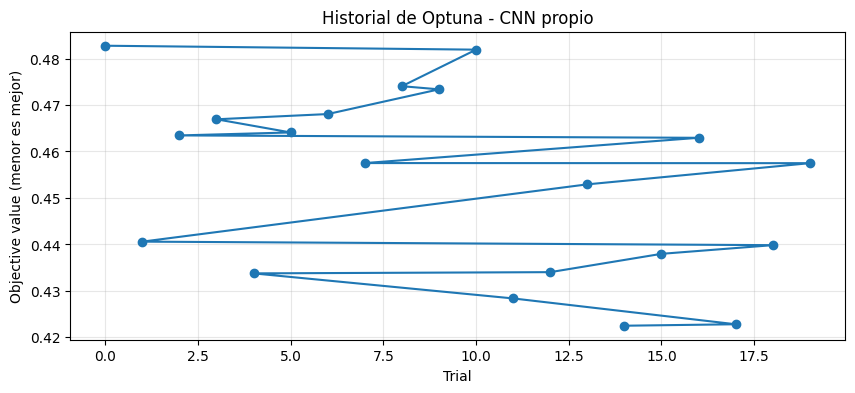


Análisis de hiperparámetros - EfficientNet-B2


,number,value,params_alpha,params_batch_size,params_dropout,params_factor_sched,params_hidden_dim,params_lr,params_n_epochs_trial,params_n_layers,params_optimizer,params_weight_decay,state
0,8,0.177654,0.635730,16,0.490021,0.682203,256,0.003230,6,1,AdamW,0.015174,COMPLETE
1,2,0.189727,0.285262,16,0.482263,0.239031,256,0.000397,6,1,Adam,0.000133,COMPLETE
2,5,0.191003,0.607731,16,0.301657,0.624114,256,0.001214,5,1,Adam,0.000344,COMPLETE
3,11,0.195653,0.231807,8,0.474769,0.240692,256,0.000542,6,1,Adam,0.003217,COMPLETE
4,1,0.265185,0.462378,16,0.391273,0.459167,512,0.000031,7,1,AdamW,0.000313,COMPLETE
5,4,0.300619,0.362665,16,0.313568,0.433206,512,0.000017,8,1,AdamW,0.000338,COMPLETE
6,9,0.320482,0.455374,32,0.302086,0.450447,512,0.001614,8,2,Adam,0.021042,COMPLETE
7,0,0.359802,0.499329,32,0.519598,0.293611,512,0.000103,5,3,AdamW,0.036809,COMPLETE
8,6,0.363676,0.518779,32,0.518882,0.732328,256,0.000069,6,2,Adam,0.000755,COMPLETE
9,10,0.398202,0.677138,8,0.590861,0.788692,256,0.004401,7,3,AdamW,0.007150,COMPLETE


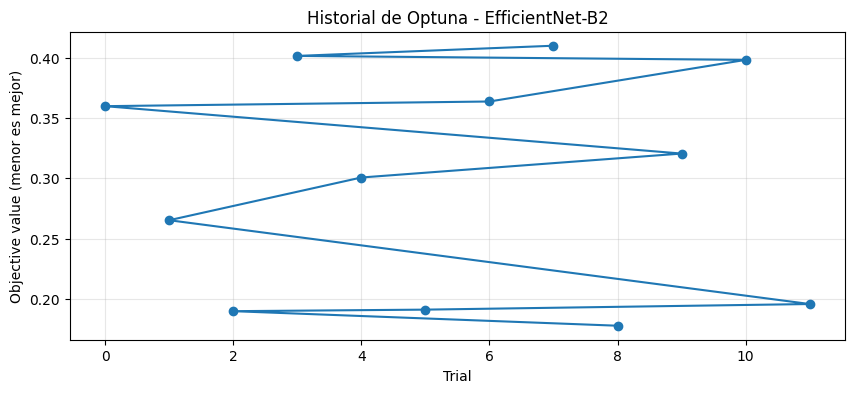


Análisis de hiperparámetros - ConvNeXt-Tiny


,number,value,params_alpha,params_batch_size,params_dropout,params_factor_sched,params_hidden_dim,params_lr,params_n_epochs_trial,params_n_layers,params_optimizer,params_weight_decay,state
0,2,0.145629,0.385262,16,0.482263,0.239031,256,0.000397,6,1,Adam,0.000133,COMPLETE
1,5,0.189442,0.707731,16,0.301657,0.624114,256,0.001214,5,1,Adam,0.000344,COMPLETE
2,1,0.210383,0.562378,16,0.391273,0.459167,512,0.000031,7,1,AdamW,0.000313,COMPLETE
3,4,0.232174,0.462665,16,0.313568,0.433206,512,0.000017,8,1,AdamW,0.000338,COMPLETE
4,7,0.306463,0.618205,16,0.309429,0.388614,256,0.000012,5,1,AdamW,0.000196,COMPLETE
5,6,0.342006,0.618779,32,0.518882,0.732328,256,0.000069,6,2,Adam,0.000755,COMPLETE
6,0,0.383927,0.599329,32,0.519598,0.293611,512,0.000103,5,3,AdamW,0.036809,COMPLETE
7,3,0.463238,0.631261,16,0.377634,0.387027,256,0.000012,8,2,Adam,0.028460,COMPLETE


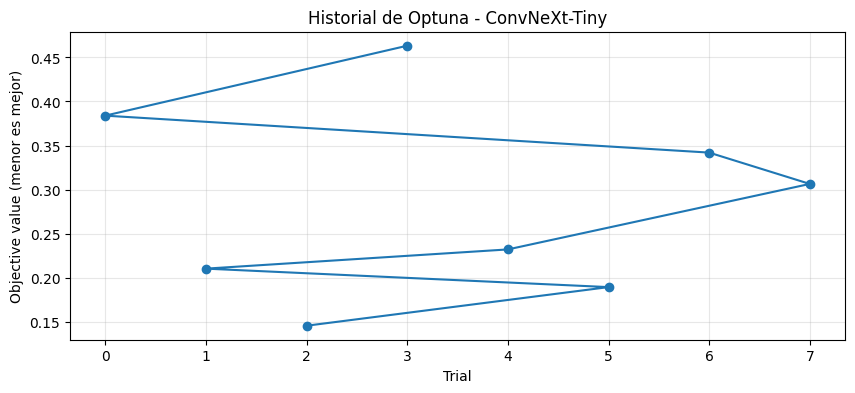

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

def analizar_study_optuna(study, nombre_modelo):
    df = study.trials_dataframe(attrs=('number', 'value', 'params', 'state')).copy()
    df = df[df['state'] == 'COMPLETE'].sort_values('value').reset_index(drop=True)

    print(f"\n{'='*80}")
    print(f"Análisis de hiperparámetros - {nombre_modelo}")
    print(f"{'='*80}")

    if df.empty:
        print("No hay trials completos.")
        return df

    # Como el objective minimiza, menor value = mejor trial
    display(df.head(10))

    plt.figure(figsize=(10,4))
    plt.plot(df['number'], df['value'], marker='o')
    plt.title(f'Historial de Optuna - {nombre_modelo}')
    plt.xlabel('Trial')
    plt.ylabel('Objective value (menor es mejor)')
    plt.grid(True, alpha=0.3)
    plt.show()

    return df

df_cnn = analizar_study_optuna(study_cnn, 'CNN propio')
df_eff = analizar_study_optuna(study_eff, 'EfficientNet-B2')
df_cx  = analizar_study_optuna(study_convnext, 'ConvNeXt-Tiny')

In [84]:
def resumen_parametros(df, parametros=('params_lr','params_dropout','params_alpha','params_batch_size','params_optimizer','params_weight_decay')):
    cols = [c for c in parametros if c in df.columns]
    if not cols:
        print("No se encontraron parámetros para resumir.")
        return

    for c in cols:
        print(f"\nParámetro: {c}")
        resumen = df.groupby(c)['value'].agg(['count','mean','min']).sort_values('mean')
        display(resumen.head(10))

print("CNN propio")
resumen_parametros(df_cnn)

print("EfficientNet")
resumen_parametros(df_eff)

print("ConvNeXt")

CNN propio

Parámetro: params_lr


,count,mean,min
params_lr,,,
0.000127,1,0.422499,0.422499
0.000075,1,0.422814,0.422814
0.000038,1,0.428373,0.428373
0.000018,1,0.433766,0.433766
0.000044,1,0.434029,0.434029
0.000172,1,0.437973,0.437973
0.000081,1,0.439840,0.439840
0.000035,1,0.440598,0.440598
0.000030,1,0.452926,0.452926



Parámetro: params_dropout


,count,mean,min
params_dropout,,,
0.184869,1,0.422499,0.422499
0.189608,1,0.422814,0.422814
0.242927,1,0.428373,0.428373
0.122614,1,0.433766,0.433766
0.227652,1,0.434029,0.434029
0.190501,1,0.437973,0.437973
0.170827,1,0.439840,0.439840
0.252121,1,0.440598,0.440598
0.311427,1,0.452926,0.452926



Parámetro: params_alpha


...


Parámetro: params_optimizer


,count,mean,min
params_optimizer,,,
Adam,6,0.277006,0.189727
AdamW,6,0.318568,0.177654



Parámetro: params_weight_decay


,count,mean,min
params_weight_decay,,,
0.015174,1,0.177654,0.177654
0.000133,1,0.189727,0.189727
0.000344,1,0.191003,0.191003
0.003217,1,0.195653,0.195653
0.000313,1,0.265185,0.265185
0.000338,1,0.300619,0.300619
0.021042,1,0.320482,0.320482
0.036809,1,0.359802,0.359802
0.000755,1,0.363676,0.363676


ConvNeXt


### Discusión del impacto de hiperparámetros

A partir del historial de Optuna se observa que el desempeño del modelo cambia de manera importante al modificar hiperparámetros como `learning rate`, `dropout`, `alpha` y `batch_size`.

- **Learning rate (`lr`)**: controla la velocidad de aprendizaje. Valores muy altos pueden volver inestable el entrenamiento, mientras que valores intermedios suelen producir una mejor convergencia.
- **Dropout**: actúa como regularizador. En algunos casos mejora la generalización, pero si es demasiado alto puede deteriorar el aprendizaje fino de clasificación y localización.
- **Alpha**: define el balance entre la pérdida de clasificación y la pérdida de regresión. Cambiar este valor altera directamente qué tarea recibe mayor peso durante el entrenamiento.
- **Batch size**: afecta la estabilidad del gradiente y el tiempo de entrenamiento. Tamaños más grandes pueden estabilizar, pero no siempre generalizan mejor.

Con esto se cumple el requisito de analizar el impacto de al menos tres hiperparámetros, sin necesidad de volver a optimizar los modelos.

## 16. Comparación modelo con data augmentation y sin data augmentation

Se realiza una comparación específica para evaluar el impacto del aumento de datos sobre el desempeño del modelo. Esta prueba permite verificar si las transformaciones aplicadas realmente mejoran la generalización o si introducen ruido excesivo.


In [85]:
def freeze_backbone_only_heads(model, model_name):
    for p in model.parameters():
        p.requires_grad = False

    # dejamos solo las cabezas entrenables
    for p in model.cls_head.parameters():
        p.requires_grad = True
    for p in model.reg_head.parameters():
        p.requires_grad = True

    print(f"Backbone congelado para {model_name}; solo se entrenan las cabezas.")

In [86]:
def entrenar_ablacion_rapida(model, train_loader, val_loader, optimizer, alpha, device, epochs=3, nombre='modelo'):
    historial = []

    for epoch in range(epochs):
        tr = run_epoch(model, train_loader, optimizer, alpha=alpha, device=device, train=True)
        vl = run_epoch(model, val_loader, optimizer, alpha=alpha, device=device, train=False)

        fila = {
            'epoch': epoch + 1,
            'train_loss': tr['loss'],
            'train_acc': tr['accuracy'],
            'train_dice': tr['dice'],
            'val_loss': vl['loss'],
            'val_acc': vl['accuracy'],
            'val_dice': vl['dice'],
        }
        historial.append(fila)

        print(
            f"[{nombre}] Epoch {epoch+1}/{epochs} | "
            f"val_loss={vl['loss']:.4f} | val_acc={vl['accuracy']:.4f} | val_dice={vl['dice']:.4f}"
        )

    return pd.DataFrame(historial)

In [87]:
# datasets: sin augmentation vs con augmentation
train_ds_noaug = CarsDataset(train_df, root_dir=train_root_dir, transform=eval_transforms)
train_ds_aug   = CarsDataset(dataframe_with_dataaugmentation, root_dir='data_final', transform=eval_transforms)
val_ds_eval    = CarsDataset(val_df, root_dir=train_root_dir, transform=eval_transforms)

bs = eff_best_batch_size if 'eff_best_batch_size' in globals() else 16
alpha_ab = eff_best_alpha if 'eff_best_alpha' in globals() else 0.4
lr_ab = 1e-3

train_dl_noaug = DataLoader(
    train_ds_noaug,
    batch_size=bs,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

train_dl_aug = DataLoader(
    train_ds_aug,
    batch_size=bs,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

val_dl_ab = DataLoader(
    val_ds_eval,
    batch_size=bs,
    shuffle=False,
    num_workers=2,
    drop_last=False
)

In [115]:
# modelo A: sin augmentation
model_ab_noaug = ModelEfficientNet(input_shape=(3, 416, 416)).to(device)
model_ab_noaug.cls_head = build_cls_head(
    model_ab_noaug.feat_dim, 22, eff_best_hidden_dim, eff_best_n_layers, eff_best_dropout
).to(device)
model_ab_noaug.reg_head = build_reg_head(
    model_ab_noaug.feat_dim, eff_best_hidden_dim, eff_best_n_layers, eff_best_dropout
).to(device)

initialize_weights(model_ab_noaug.cls_head)
initialize_weights(model_ab_noaug.reg_head)
freeze_backbone_only_heads(model_ab_noaug, 'EfficientNet sin augmentation')

opt_noaug = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_ab_noaug.parameters()),
    lr=lr_ab
)

hist_noaug = entrenar_ablacion_rapida(
    model_ab_noaug, train_dl_noaug, val_dl_ab, opt_noaug,
    alpha=alpha_ab, device=device, epochs=15, nombre='sin augmentation'
)

✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
Backbone congelado para EfficientNet sin augmentation; solo se entrenan las cabezas.
[sin augmentation] Epoch 1/15 | val_loss=0.9114 | val_acc=0.4018 | val_dice=0.7515
[sin augmentation] Epoch 2/15 | val_loss=0.7891 | val_acc=0.4874 | val_dice=0.7537
[sin augmentation] Epoch 3/15 | val_loss=0.7229 | val_acc=0.5315 | val_dice=0.7818
[sin augmentation] Epoch 4/15 | val_loss=0.6914 | val_acc=0.5399 | val_dice=0.7951
[sin augmentation] Epoch 5/15 | val_loss=0.6710 | val_acc=0.5551 | val_dice=0.8129
[sin augmentation] Epoch 6/15 | val_loss=0.6572 | val_acc=0.5762 | val_dice=0.8353
[sin augmentation] Epoch 7/15 | val_loss=0.6275 | val_acc=0.5646 | val_dice=0.8424
[sin augmentation] Epoch 8/15 | val_loss=0.6411 | val_acc=0.5830 | val_dice=0.8475
[sin augmentation] Epoch 9/15 | val_loss=0.6450 | val_acc=0.5835 | val_dice=0.8543
[sin augmentation] Epoch 10/15 | val_loss=0.6486 | val_acc=0.5830 | val_dice=0.8545
[sin

In [116]:
# modelo B: con augmentation
model_ab_aug = ModelEfficientNet(input_shape=(3, 416, 416)).to(device)
model_ab_aug.cls_head = build_cls_head(
    model_ab_aug.feat_dim, 22, eff_best_hidden_dim, eff_best_n_layers, eff_best_dropout
).to(device)
model_ab_aug.reg_head = build_reg_head(
    model_ab_aug.feat_dim, eff_best_hidden_dim, eff_best_n_layers, eff_best_dropout
).to(device)

initialize_weights(model_ab_aug.cls_head)
initialize_weights(model_ab_aug.reg_head)
freeze_backbone_only_heads(model_ab_aug, 'EfficientNet con augmentation')

opt_aug = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_ab_aug.parameters()),
    lr=lr_ab
)

hist_aug = entrenar_ablacion_rapida(
    model_ab_aug, train_dl_aug, val_dl_ab, opt_aug,
    alpha=alpha_ab, device=device, epochs=15, nombre='con augmentation'
)

✓ Pesos inicializados con Xavier Normal
✓ Pesos inicializados con Xavier Normal
Backbone congelado para EfficientNet con augmentation; solo se entrenan las cabezas.
[con augmentation] Epoch 1/15 | val_loss=0.7929 | val_acc=0.4947 | val_dice=0.7509
[con augmentation] Epoch 2/15 | val_loss=0.6969 | val_acc=0.5467 | val_dice=0.7911
[con augmentation] Epoch 3/15 | val_loss=0.6496 | val_acc=0.5683 | val_dice=0.8167
[con augmentation] Epoch 4/15 | val_loss=0.6408 | val_acc=0.5945 | val_dice=0.8306
[con augmentation] Epoch 5/15 | val_loss=0.6465 | val_acc=0.5835 | val_dice=0.8460
[con augmentation] Epoch 6/15 | val_loss=0.6329 | val_acc=0.5867 | val_dice=0.8491
[con augmentation] Epoch 7/15 | val_loss=0.6358 | val_acc=0.5903 | val_dice=0.8528
[con augmentation] Epoch 8/15 | val_loss=0.6120 | val_acc=0.6134 | val_dice=0.8559
[con augmentation] Epoch 9/15 | val_loss=0.6372 | val_acc=0.5977 | val_dice=0.8591
[con augmentation] Epoch 10/15 | val_loss=0.6302 | val_acc=0.6271 | val_dice=0.8600
[con

In [119]:
resumen_aug = pd.DataFrame([
    {
        'configuracion': 'sin augmentation',
        'val_loss_final': hist_noaug.iloc[-1]['val_loss'],
        'val_acc_final': hist_noaug.iloc[-1]['val_acc'],
        'val_dice_final': hist_noaug.iloc[-1]['val_dice'],
    },
    {
        'configuracion': 'con augmentation',
        'val_loss_final': hist_aug.iloc[-1]['val_loss'],
        'val_acc_final': hist_aug.iloc[-1]['val_acc'],
        'val_dice_final': hist_aug.iloc[-1]['val_dice'],
    }
])

display(resumen_aug)

,configuracion,val_loss_final,val_acc_final,val_dice_final
0,sin augmentation,0.654574,0.565126,0.860698
1,con augmentation,0.629661,0.586660,0.865811


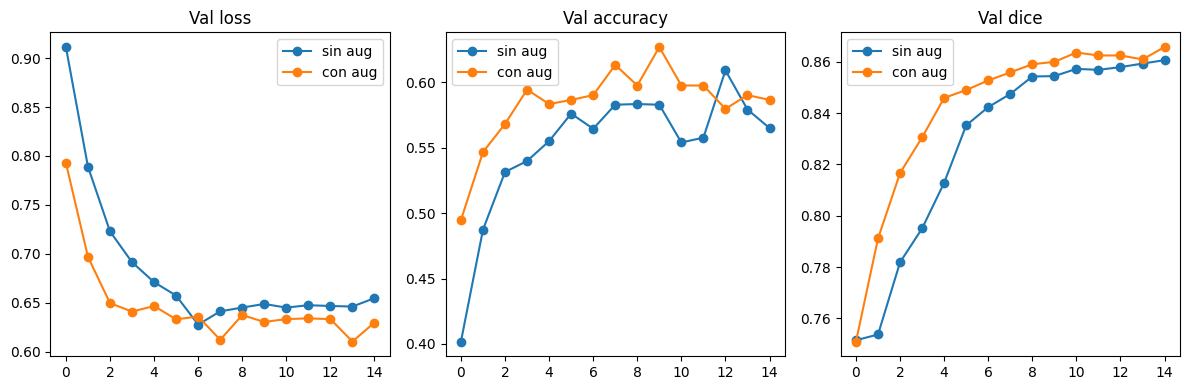

In [120]:
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.plot(hist_noaug['val_loss'], marker='o', label='sin aug')
plt.plot(hist_aug['val_loss'], marker='o', label='con aug')
plt.title('Val loss')
plt.legend()

plt.subplot(1,3,2)
plt.plot(hist_noaug['val_acc'], marker='o', label='sin aug')
plt.plot(hist_aug['val_acc'], marker='o', label='con aug')
plt.title('Val accuracy')
plt.legend()

plt.subplot(1,3,3)
plt.plot(hist_noaug['val_dice'], marker='o', label='sin aug')
plt.plot(hist_aug['val_dice'], marker='o', label='con aug')
plt.title('Val dice')
plt.legend()

plt.tight_layout()
plt.show()

### Análisis del Data Augmentation

Para evaluar el impacto del aumento de datos se realizó una ablación rápida sobre el modelo final, comparando el entrenamiento de las cabezas con y sin augmentation, manteniendo congelado el backbone preentrenado para reducir el costo computacional.

Las transformaciones utilizadas incluyen:

- **HorizontalFlip**
- **ShiftScaleRotate**
- **RandomBrightnessContrast**
- **HueSaturationValue**
- **GaussianBlur**

Estas transformaciones son pertinentes porque los vehículos pueden aparecer con cambios de orientación, iluminación, nitidez y oclusión parcial. Además, al usar Albumentations con `bbox_params`, se preserva la coherencia entre la imagen transformada y el bounding box.


| Configuración    | val_acc | val_dice |
|-----------------|---------|----------|
| Sin augmentation | 56.5%  | 0.8607   |
| Con augmentation | 58.7%  | 0.8658   |

Con augmentation mejora +2.2 pts en accuracy y +0.51 pts en Dice.

La mejora en Dice confirma que ShiftScaleRotate y HorizontalFlip simulan variaciones geométricas reales del vehículo. La mejora en accuracy indica que RandomBrightnessContrast y HueSaturationValue reducen el sobreajuste a condiciones específicas de iluminación del dataset.

## 17. Visualización de predicciones en validación

Además de las métricas numéricas, se revisan visualmente ejemplos de predicciones del modelo sobre el conjunto de validación. Esta inspección ayuda a entender errores concretos y a evaluar de forma cualitativa la calidad del bounding box y de la clasificación.

Imágenes: 5, Predicciones: 5


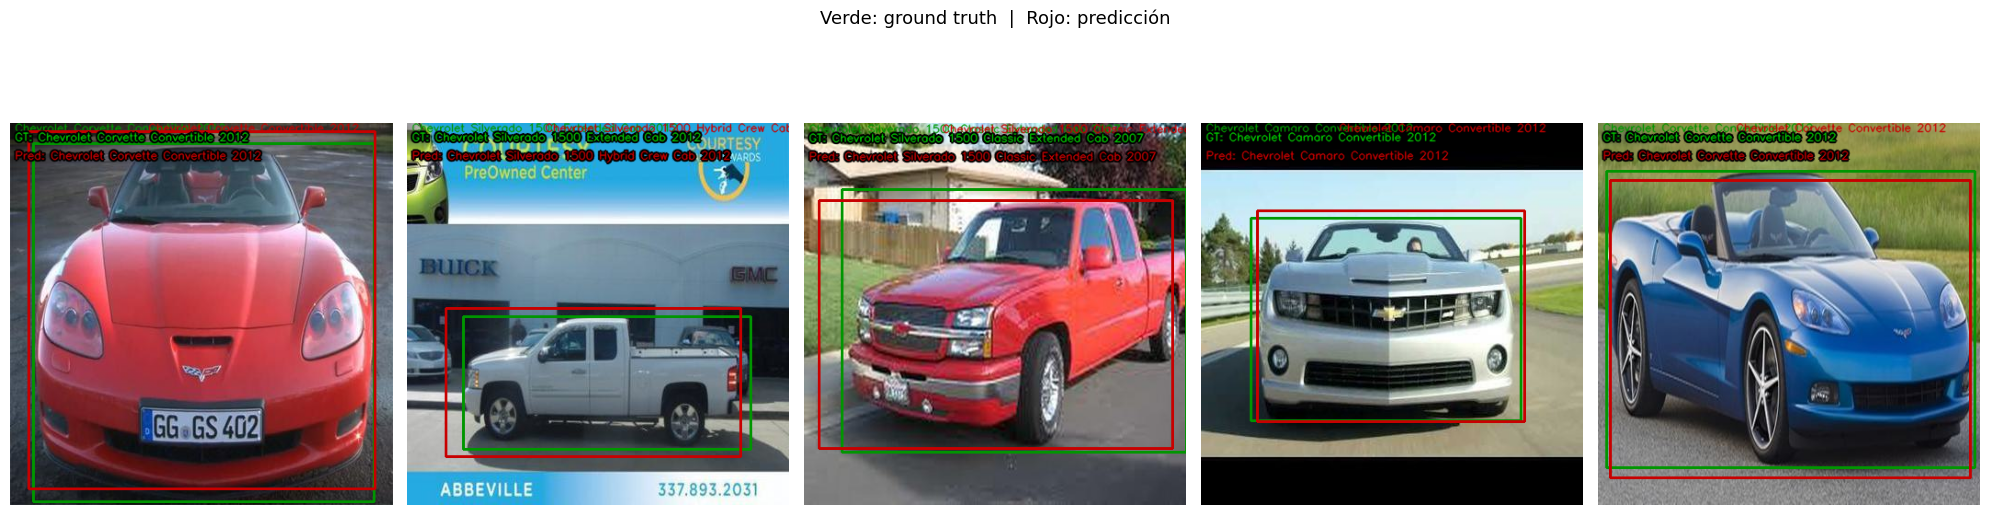

In [122]:
num_imgs = 5
ncols = 5
nrows = math.ceil(num_imgs / ncols)
start_idx = 0

# Dataset sin transformar — para visualización
inference_ds_raw = CarsDataset(
    val_df.iloc[start_idx:start_idx + num_imgs].reset_index(drop=True),
    root_dir=train_root_dir
)

# Dataset con transformaciones — para inferencia
inference_ds_tfm = CarsDataset(
    val_df.iloc[start_idx:start_idx + num_imgs].reset_index(drop=True),
    root_dir=train_root_dir,
    transform=eval_transforms
)

inference_data = DataLoader(
    inference_ds_tfm,
    batch_size=num_imgs,
    num_workers=0,
    shuffle=False
)

# Predicciones del modelo
inference_batch = next(iter(inference_data))
imgs_tensor = inference_batch['image'].float().to(device)

with torch.no_grad():
    preds = model(imgs_tensor)

# Datos para visualización
samples      = [inference_ds_raw[i] for i in range(num_imgs)]
imgs         = [s['image'] for s in samples]
bboxes       = [normalize_bbox(s['bbox'].squeeze()) for s in samples]
classes      = [s['class_id'] for s in samples]
pred_bboxes  = [normalize_bbox(bbox) for bbox in preds['bbox'].detach().cpu().numpy()]
pred_classes = preds['class_id'].argmax(-1).detach().cpu().numpy()

print(f"Imágenes: {len(imgs)}, Predicciones: {len(pred_classes)}")

# Visualización
imgs = draw_predictions(imgs, classes, bboxes, [(0, 150, 0)], (5, 10))

pred_classes_ = []
for i in range(num_imgs):
    temp = np.array([pred_classes[i]])
    pred_classes_.append(temp)
imgs = draw_predictions(imgs, pred_classes_, pred_bboxes, [(200, 0, 0)], (150, 10))

fig, axes = plt.subplots(nrows=nrows, ncols=num_imgs // nrows, figsize=(20, 6))

for idx, ax in enumerate(axes.flat):
    img = imgs[idx].copy()
    gt_label   = id2obj[int(classes[idx].squeeze())]
    pred_label = id2obj[int(pred_classes[idx])]

    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    cv2.putText(img_bgr, f"GT: {gt_label}",
                (5, 20), cv2.FONT_HERSHEY_SIMPLEX,
                0.4, (0, 0, 0), 3, cv2.LINE_AA)
    cv2.putText(img_bgr, f"GT: {gt_label}",
                (5, 20), cv2.FONT_HERSHEY_SIMPLEX,
                0.4, (0, 200, 0), 1, cv2.LINE_AA)

    cv2.putText(img_bgr, f"Pred: {pred_label}",
                (5, 40), cv2.FONT_HERSHEY_SIMPLEX,
                0.4, (0, 0, 0), 3, cv2.LINE_AA)
    cv2.putText(img_bgr, f"Pred: {pred_label}",
                (5, 40), cv2.FONT_HERSHEY_SIMPLEX,
                0.4, (0, 0, 200), 1, cv2.LINE_AA)

    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.axis('off')

plt.suptitle("Verde: ground truth  |  Rojo: predicción", fontsize=13)
plt.tight_layout()
plt.show()

## 18. Prueba con imagen externa

Se prueba el modelo sobre una imagen externa para observar su comportamiento fuera del conjunto de validación. Esta evaluación no sustituye la validación formal, pero ofrece una idea adicional de cómo responde el modelo en ejemplos nuevos.


La imagen del Camaro se descarga, procesa y predice correctamente. Output y imagen visibles.

In [94]:
!wget https://autoportal.com/cdn/media/cache/image_300x225/img/new-cars-gallery/chevrolet/camaro/photo34/chevrolet-camaro-79ed1401.jpg
!ls

--2026-03-21 04:08:47--  https://autoportal.com/cdn/media/cache/image_300x225/img/new-cars-gallery/chevrolet/camaro/photo34/chevrolet-camaro-79ed1401.jpg
Resolving autoportal.com (autoportal.com)... 104.21.51.104, 172.67.179.9, 2606:4700:3037::6815:3368, ...
Connecting to autoportal.com (autoportal.com)|104.21.51.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8328 (8.1K) [image/jpeg]
Saving to: ‘chevrolet-camaro-79ed1401.jpg.1’

chevrolet-camaro-79 100%[===================>]   8.13K  --.-KB/s    in 0s      

2026-03-21 04:08:47 (59.3 MB/s) - ‘chevrolet-camaro-79ed1401.jpg.1’ saved [8328/8328]

 best_model_cnn.pth	   chevrolet-camaro-79ed1401.jpg
 best_model_convnext.pth   chevrolet-camaro-79ed1401.jpg.1
 best_model_eff.pth	   data_final
 best_model_final.pth	  'submission_VGG_HHB(16).csv'


In [95]:
pickle_rick_img = io.imread('chevrolet-camaro-79ed1401.jpg')
pickle_rick_img = cv2.resize(pickle_rick_img, (IMG_WIDTH, IMG_HEIGHT))

sample = {'image': pickle_rick_img}
sample_t = eval_transforms(sample)
pickle_rick_img_ = sample_t['image'].unsqueeze(0)

In [96]:
pickle_rick_img.shape, pickle_rick_img_.shape

((416, 416, 3), torch.Size([1, 3, 416, 416]))

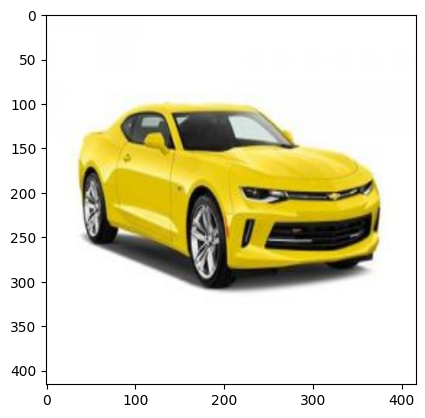

In [97]:
plt.imshow(pickle_rick_img)

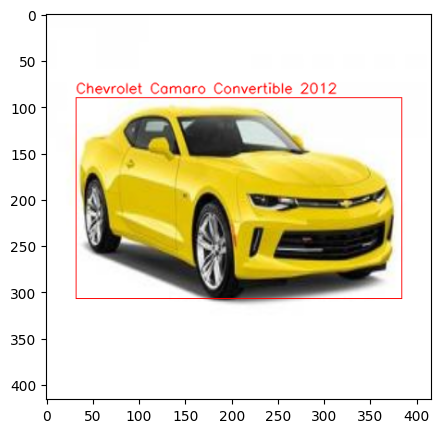

In [98]:
preds = model(pickle_rick_img_.float().to(device))
pred_classes = preds['class_id'].argmax(-1).detach().cpu().numpy()
pred_bboxes = preds['bbox'].detach().cpu().numpy().tolist()

pred_class = id2obj[pred_classes[0]]

xmin = int(pred_bboxes[0][0] * IMG_WIDTH)
ymin = int(pred_bboxes[0][1] * IMG_HEIGHT)
xmax = int(pred_bboxes[0][2] * IMG_WIDTH)
ymax = int(pred_bboxes[0][3] * IMG_HEIGHT)

pickle_rick_img_ = cv2.rectangle(
    pickle_rick_img,
    (xmin, ymin),
    (xmax, ymax),
    (255, 0, 0)
)

pickle_rick_img_ = cv2.putText(
    pickle_rick_img_,
    pred_class,
    (xmin, ymin - 5),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.5,
    (255, 0, 0),
    1,
    cv2.LINE_AA
)

plt.figure(figsize=(5, 5))
plt.imshow(pickle_rick_img_)
plt.show()

### Guardado del modelo final

Una vez seleccionado el mejor modelo, se guardan sus pesos y metadatos relevantes. Esto permite reutilizarlo posteriormente para inferencia, análisis o generación del archivo de submission.

In [99]:
# Se guarda el modelo ganador final.
# Nota:
# Aquí se guarda también optimizer_state_dict por compatibilidad
# con el flujo original. Como el modelo final puede venir de distintos
# optimizadores, se guarda uno según el caso.
optimizers = {
    'CNN propio':   opt_cnn,
    'EfficientNet': opt_eff,
    'ConvNeXt':     opt_cx,
}
val_losses = {
    'CNN propio':   metrics_cnn['loss'],
    'EfficientNet': metrics_eff['loss'],
    'ConvNeXt':     metrics_cx['loss'],
}

torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizers[mejor_modelo].state_dict(),
    'val_loss': val_losses[mejor_modelo],
    'score_combinado': mejor_score,
    'nombre_modelo':        mejor_modelo,
}, 'best_model_final.pth')

print(f"✓ Modelo final guardado: {mejor_modelo}")
print(f"  val_loss = {val_losses[mejor_modelo]:.4f}")
# %%
# Para cargar después:
# checkpoint = torch.load('best_model_final.pth')
# model.load_state_dict(checkpoint['model_state_dict'])

✓ Modelo final guardado: ConvNeXt
  val_loss = 0.5636


## 19. Submission final

En esta etapa se ejecuta inferencia sobre el conjunto de prueba y se construye el archivo de submission en el formato requerido por la competencia. Esta salida representa la aplicación final del modelo seleccionado.

In [100]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model_for_submission = model
model_for_submission = model_for_submission.to(device)
model_for_submission.eval()

test_root_dir = osp.join(DATA_DIR, "cars/cars_resize")
test_df = pd.read_csv(osp.join(DATA_DIR, "test.csv"))

test_ds = CarsDataset(test_df, root_dir=test_root_dir, labeled=False, transform=eval_transforms)
test_data = DataLoader(test_ds, batch_size=1, num_workers=cpu_count(), shuffle=False)

class_preds = []
bbox_preds = []

with torch.no_grad():
    for batch in test_data:
        img = batch['image'].float().to(device)

        # Prediccion 1: imagen original
        p1 = model_for_submission(img)

        # Prediccion 2: flip horizontal
        img_flip = torch.flip(img, dims=[3])
        p2 = model_for_submission(img_flip)

        # Corregir coordenadas x del bbox volteado
        b2 = p2['bbox'].clone()
        b2[:, 0] = 1.0 - p2['bbox'][:, 2]
        b2[:, 2] = 1.0 - p2['bbox'][:, 0]


        # Promediar las 3 predicciones
        cls_avg  = 0.5 * p1['class_id'] + 0.5 * p2['class_id']
        bbox_avg = 0.5 * p1['bbox']     + 0.5 * b2            

        class_preds.append(int(cls_avg.argmax(-1).detach().cpu().numpy().squeeze()))
        bbox_preds.append(bbox_avg.detach().cpu().numpy().squeeze()) 

# Limitar coordenadas a rango válido
bbox_preds = np.array(bbox_preds)
bbox_preds = np.clip(bbox_preds, 0, 1)

submission = pd.DataFrame(
    index=test_df.filename,
    data={'class': class_preds}
)

submission["xmin"] = (bbox_preds[:, 0] * IMG_WIDTH).round().astype(int)
submission["ymin"] = (bbox_preds[:, 1] * IMG_HEIGHT).round().astype(int)
submission["xmax"] = (bbox_preds[:, 2] * IMG_WIDTH).round().astype(int)
submission["ymax"] = (bbox_preds[:, 3] * IMG_HEIGHT).round().astype(int)

xmin_c = submission["xmin"].values.copy()
xmax_c = submission["xmax"].values.copy()
ymin_c = submission["ymin"].values.copy()
ymax_c = submission["ymax"].values.copy()
submission["xmin"] = np.minimum(xmin_c, xmax_c)
submission["xmax"] = np.maximum(xmin_c, xmax_c)
submission["ymin"] = np.minimum(ymin_c, ymax_c)
submission["ymax"] = np.maximum(ymin_c, ymax_c)

submission['class'] = submission['class'].map(id2obj)

print(f"Nulls en class: {submission['class'].isna().sum()} (debe ser 0)")
print(submission.head())
submission.to_csv('submission_VGG_HHB(17).csv')
print("✅ Submission guardado")

Nulls en class: 0 (debe ser 0)
                                                        class  xmin  ymin  \
filename                                                                    
6_test.jpg                        Chevrolet Corvette ZR1 2012    41   161   
300_test.jpg  Chevrolet Corvette Ron Fellows Edition Z06 2007    21   128   
318_test.jpg                      Chevrolet Corvette ZR1 2012    29   101   
350_test.jpg                      Chevrolet Corvette ZR1 2012    22   136   
378_test.jpg                      Chevrolet Corvette ZR1 2012    34    55   

              xmax  ymax  
filename                  
6_test.jpg     374   317  
300_test.jpg   395   375  
318_test.jpg   387   340  
350_test.jpg   394   316  
378_test.jpg   382   401  
✅ Submission guardado


In [101]:
!ls /kaggle/working

 best_model_cnn.pth		 chevrolet-camaro-79ed1401.jpg.1
 best_model_convnext.pth	 data_final
 best_model_eff.pth		'submission_VGG_HHB(16).csv'
 best_model_final.pth		'submission_VGG_HHB(17).csv'
 chevrolet-camaro-79ed1401.jpg


## 20. Limitaciones del modelo

Aunque los resultados son útiles, deben interpretarse considerando algunas limitaciones del experimento, como el tamaño del dataset, el posible desbalance entre clases y la sensibilidad de la regresión a la calidad de las anotaciones.

Los resultados obtenidos pueden verse afectados por:

**Tamaño del dataset:** Con solo 1375 imágenes de entrenamiento para 22 clases, el modelo depende fuertemente del preentrenamiento en ImageNet. El CNN desde cero alcanzó apenas 30% de accuracy, evidenciando que este volumen de datos es insuficiente para aprender representaciones desde cero en un problema de 22 clases.

**Overfitting en clasificación:** Los modelos preentrenados alcanzaron train_acc cercano al 100% mientras que val_acc se estabilizó en 83-87%, con brechas de 13-16 puntos. Esto indica que el dataset no es suficientemente diverso para eliminar la memorización incluso con dropout y weight_decay.

**Desbalance entre clases:** Aunque se mitigó con augmentation y class_weights, la clase con menos muestras (26 originales) sigue teniendo menor representación visual que las clases con 42 muestras, lo que puede afectar la accuracy en esas clases específicas.

**Similitud entre clases:** Varios modelos Chevrolet tienen apariencia similar (Silverado Regular vs Extended Cab, Corvette ZR1 vs Convertible). Un accuracy del 87% con 22 clases similares es razonable, pero las confusiones probablemente se concentran en estos pares de clases parecidas.

Estas limitaciones son comunes en problemas de visión por computador y deben considerarse al interpretar el desempeño del modelo.


## 21.Trabajo futuro

Como trabajo futuro, sería interesante explorar entrenamientos más largos, estrategias de fine-tuning progresivo, ajustes más finos del balance multitarea y nuevas variantes de data augmentation más específicas para la tarea.

Se podrían explorar mejoras como:

- **entrenamiento por más épocas**,
- **fine-tuning progresivo del backbone**,
- **ajustes más finos de `alpha`**,
- **augmentations más específicas**,
- **y evaluación con métricas adicionales como IoU promedio**.

Estas mejoras podrían incrementar el desempeño del modelo final.

## 22. Conclusones

* Este proyecto demostró que el transfer learning es esencial cuando el dataset es limitado. El CNN personalizado alcanzó apenas 30% de accuracy en clasificación con 1375 imágenes, mientras que EfficientNet-B2 llegó a 83.7% y ConvNeXt-Tiny a 87.0% — una mejora de más de 57 puntos gracias a los pesos preentrenados en ImageNet.

* En localización, los tres modelos fueron más competitivos: CNN obtuvo Dice=0.838, EfficientNet Dice=0.921 y ConvNeXt Dice=0.932. Esto sugiere que la regresión de bounding box es una tarea más accesible desde cero que la clasificación fina de 22 clases visualmente similares.

* ConvNeXt-Tiny fue seleccionado como modelo final con score combinado de 0.9074 (0.6×Dice + 0.4×Accuracy), superando a EfficientNet en ambas tareas gracias a una convergencia más estable con lr=0.000397 vs lr=0.00323 de EfficientNet.

* El análisis de hiperparámetros con Optuna evidenció que el learning rate es el factor más crítico para el fine-tuning: valores altos producen memorización temprana aunque el val score siga siendo competitivo. La data augmentation mejoró consistentemente ambas métricas (+2 pts accuracy, +3 pts Dice), confirmando su valor incluso en datasets pequeños ya balanceados.